<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_RobQFL_Maouaki2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Robust quantum federated learning (RobQFL) against PGD attacks: Maouaki et al. (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Walid El Maouaki, Nouhaila Innan, Alberto Marchisio, Taoufik Said, Muhammad Shafique and Mohamed Bennai,
> "RobQFL: Robust Quantum Federated Learning in Adversarial Environment",
> *IEEE International Conference on Quantum Artificial Intelligence (QAI)* 2025, DOI [10.1109/QAI63978.2025.00027](https://doi.org/10.1109/qai63978.2025.00027), arXiv:2509.04914.

**What the notebook does.** Fifteen simulated clients train one 4-qubit quantum neural network with Federated Averaging (FedAvg) on three-class MNIST
(digits 0, 1, 2) and three-class Fashion-MNIST (T-shirt, trouser, pullover). An attacker applies untargeted **PGD** to the input pixels. The notebook (i) shows that the federated model is as fragile
as a centrally trained one, (ii) adds the paper's *RobQFL* defence, which is adversarial training inside the federated loop with three tunable knobs (the **coverage** gamma = share of clients that train
adversarially, the **epsilon schedule** = one radius or a cyclic mix of radii, and **fine-tune vs scratch**), (iii) summarises every gamma x epsilon accuracy surface with the paper's two scores,
the **Accuracy-Robustness Area (ARA)** and the **Robustness Volume (RV)**, and (iv) repeats the experiments on label-sorted **non-IID** shards. Every number is put next to the paper's value with a verdict.
Besides the paper's experiments it adds what the paper lacks: a classical federated MLP trained with the same protocol on the same inputs, RandomForest / SVC baselines, a gradient-checked simulator
that is asserted equal to the PennyLane circuit, several seeds for the headline result, and a sensitivity check of the two attack settings the paper does not state.

**How to run.** Open in Google Colab (a CPU runtime is enough; no GPU, no quantum hardware, no API key), then *Runtime -> Run all*.
`FAST_MODE = True` (default in the configuration cell) uses 3000 training images and shortened budgets and finishes in about 10 minutes on a CPU;
set `FAST_MODE = False` for the paper's budgets (18000 training and 1000 test images, 50 + 30 federated rounds, all five epsilon schedules, three seeds of the headline sweep), which takes about an hour on a laptop CPU.
**What you get at the end:** the real data and class scatter plots, the circuit drawn from the QNode that is executed, the paper's Table I-IV re-computed, heat maps and robustness curves in the style of Fig. 2-4,
a classical twin, and a claim-by-claim verdict table.

## The paper in one page

**Problem.** Quantum federated learning (QFL) keeps each client's data on its device, which helps privacy, but nothing in the protocol protects the shared quantum model against *evasion* attacks:
a small, well-chosen perturbation of an input image makes quantum neural networks (QNNs) fail, just like classical networks. The paper asks (1) is QFL any more robust than centralised quantum learning,
and (2) how should adversarial training be organised when only some clients can afford it?

**Model (Section III).** K = 15 clients each own a private shard of the data. One parameterised circuit f(x; theta) is shared: the input vector is embedded in the **amplitudes of a 4-qubit register**,
**two layers of a hardware-efficient ansatz** follow, and expectation values are mapped to class logits. Each round every client runs local gradient descent and the server averages the weights (FedAvg).
Gradients come from the parameter-shift rule; simulation in PennyLane.

**Attack and defence.** Untargeted **PGD** inside an L-infinity ball of radius epsilon in [0, 0.5]. *Adversarial training (AT)* is applied on a fraction **gamma in {0, 20, 50, 75, 100} %** of the clients; every covered
client perturbs **50 %** of each mini-batch. Two schedules: **fixed-epsilon** (0.1 or 0.3) or **mixed-epsilon**, a vector of m = 3 radii handed to the adversarial clients cyclically (low [0.01, 0.02, 0.05], moderate [0.10, 0.15, 0.20], strong [0.3, 0.4, 0.5]).
Two optimisation regimes: **fine-tune** (50 clean rounds, then 30 rounds of AT warm-started from the clean model) and **scratch** (20 rounds of AT from random weights).

**Metrics.** Accuracy A(gamma, eps) on 1000 test images under attack; **ARA(gamma)** = (1/eps_max) * integral of A/100 d eps (the mean accuracy over the epsilon range, in [0, 1]); **RV** = the same average over the whole (gamma, eps) surface.

**Data.** MNIST and Fashion-MNIST, classes 0, 1, 2 only, 18000 training and 1000 test images, resized to 8 x 8; an IID split (uniform shuffle) and a label-sorted non-IID split (near single-class clients).

**Claims checked below.** (1) Table I: centralised 80.6 % vs QFL 79.5 % clean, both collapse beyond epsilon = 0.1: federation brings no robustness. (2) AT on only 20-50 % of the clients lifts accuracy for epsilon <= 0.1 by about 15 points at less than 2 points of clean accuracy.
(3) Fine-tuning beats scratch training (Table II, RV 0.151 vs 0.144). (4) With >= 75 % coverage a moderate epsilon mix is best, high-epsilon schedules only help at 100 % coverage (Table III, Fig. 3). (5) Label-sorted non-IID data roughly halves the Robustness Volume (Table IV: 0.151 -> 0.077 on MNIST, 0.154 -> 0.062 on Fashion-MNIST).

### What follows the paper and what had to be chosen

The paper gives the protocol, the knobs and the metrics, but the code is not public and several details are missing. Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit | amplitude embedding of x on 4 qubits, "two layers of a hardware-efficient ansatz", expectation values mapped to class logits | `AmplitudeEmbedding` (L2-normalised) + `StronglyEntanglingLayers(2 layers)` = 24 weights; `<Z>` of qubits 0, 1, 2 are the three class scores; logits = 5 x `<Z>`, soft-max cross-entropy (`# CHOICE`: ansatz family, read-out, loss, scale) |
| Image size vs qubits | images 8 x 8 (64 values) but a 4-qubit register (16 amplitudes) | 28 x 28 -> 8 x 8 (bilinear) -> 2 x 2 mean pooling -> 4 x 4 = 16 amplitudes (`# CHOICE`; the only way to fit 8 x 8 into 4 qubits without a different embedding) |
| Data | MNIST and Fashion-MNIST, classes 0, 1, 2, 18000 train / 1000 test | same; random subsets of the official splits (class counts as they come), `N_TRAIN` / `N_TEST` below; 1000 further images of the official test split are held out as a validation slice, used only for the learning-rate check |
| Clients and splits | K = 15; IID shuffle or label-sorted non-IID | same; sorted = images ordered by label (random inside a label), 15 contiguous shards |
| FedAvg | all clients selected, weights averaged | all 15 clients every round, plain average (equal shard sizes) |
| Local optimiser | "local gradient descent" | 5 mini-batch SGD steps of 32 images per client and round, learning rate 1.0 (`# CHOICE`; best of a small grid on the validation slice) |
| Learning-rate schedule | not stated | linear decay from 1.0 to 0.1 over the rounds of every phase (clean, fine-tune, scratch), so the last round does not oscillate (`# CHOICE`) |
| Gradients | parameter-shift rule | exact adjoint gradient of the same gate list, asserted equal to the parameter-shift rule and to finite differences (section 3); no shot noise |
| PGD | untargeted, L-infinity, epsilon in [0, 0.5]; steps, step size and pixel scaling not given | 10 steps of 2.5 eps / 10, no random start, pixels clipped to [0, 1]; **epsilon is quoted in units of `EPS_UNIT` = 0.45**, i.e. the L-infinity radius on pixels in [0, 1] is 0.45 x epsilon (`# CHOICE`, the one **calibrated** constant: it minimises the squared error to the paper's Table I QFL row for our clean model on validation images, section 10). With raw [0, 1] pixels (unit 1) the model collapses about twice as early as in Table I. Table I's attack curve is therefore calibrated rather than an independent check |
| AT clients | "first gamma share of clients" (selection rule not given); mixed schedule `eps_k = Xi[(k mod m) - 1]` | `round(gamma x 15)` clients from one fixed random permutation per seed (nested across gamma), mixed radii assigned to them cyclically |
| Epsilon grid | sweep 0.01-0.5; Table I shows 0, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5 | exactly those 7 values; ARA by the trapezoid rule on them (this reproduces the paper's ARA of the clean curve, 0.136, from Table I) |
| ARA, RV | integrals of A/100 over epsilon (and gamma) divided by eps_max (gamma_max) | trapezoid rule over epsilon and over gamma in {0, 0.2, 0.5, 0.75, 1} |
| Budgets | clean 50 rounds + 30 fine-tune rounds; scratch 20 rounds | the same in the full run (`FAST_MODE = False`); smaller in `FAST_MODE` |
| Centralised baseline | "single QNN trained centrally" | same weights initialisation, mini-batch of 15 x 32 images, as many steps as the federated model has rounds x local steps (`# CHOICE`) |
| Seeds | one run per cell | one run per cell + extra seeds for the headline experiment (mean +- std) |
| Not in the paper | - | classical federated MLP on identical inputs, RandomForest / SVC (clean and transfer attacks), PGD-strength sensitivity |

In [1]:
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
# PennyLane draws and cross-checks the circuit; the training itself uses an exact NumPy simulator (section 3).
# Colab already ships numpy, pandas, scikit-learn, matplotlib and Pillow.
if IN_COLAB or not _have("pennylane"):
    !pip -q install "pennylane==0.45.1"
    # a runtime restart is normally NOT needed; if an import below fails, restart once and Run all again

In [2]:
SEED = 42
FAST_MODE = False           # True: about 10 minutes on a CPU (small budgets); False: the paper's budgets, see the full-run line at the bottom of this cell
IBM_TOKEN = ""              # not used: the 4-qubit model is simulated exactly; kept for symmetry with the other notebooks

DATA_DIR = "qc221_data"     # MNIST / Fashion-MNIST files are cached here (or upload them into this folder)

# ---- model and federation (paper, Section III) ----
N_QUBITS, N_LAYERS = 4, 2            # 4-qubit register, two layers of the hardware-efficient ansatz
CLASSES = (0, 1, 2)                  # the three classes used for both datasets
N_CLIENTS = 15                       # K = 15 quantum clients
PRE_SIZE = 8                         # images resized to 8 x 8 ...
POOL = 2                             # ... CHOICE: then 2 x 2 mean pooling -> 4 x 4 = 16 amplitudes = exactly the 2^4 amplitudes of 4 qubits
N_TRAIN = 3000 if FAST_MODE else 18000      # paper: 18000 training images (after keeping classes 0, 1, 2)
N_TEST  = 400  if FAST_MODE else 1000       # paper: 1000 test images
EPS_GRID = [0.0, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5]    # CHOICE: the epsilons of the paper's Table I (the full sweep of the paper is 0.01-0.5)
COVERAGES = [0.0, 0.2, 0.5, 0.75, 1.0]              # gamma
ADV_FRAC = 0.5                       # rho: fraction of each mini-batch that a covered client perturbs

# ---- optimisation budgets (paper: 50 clean rounds + 30 fine-tune rounds, or 20 scratch rounds) ----
CLEAN_ROUNDS   = 15 if FAST_MODE else 50
FT_ROUNDS      = 8  if FAST_MODE else 30
SCRATCH_ROUNDS = 8  if FAST_MODE else 20
LOCAL_STEPS, BATCH, LR = 5, 32, 1.0  # CHOICE: 5 local mini-batch SGD steps of 32 images per client and round, learning rate 1.0 (paper: not stated; the best of a small grid on the validation slice, section 2)
LR_END_FRAC = 0.1                    # CHOICE: the learning rate decays linearly to 0.1 x LR over the rounds of each phase (keeps the last round from oscillating; paper: not stated)
LOGIT_SCALE = 5.0                    # CHOICE: logits = LOGIT_SCALE * <Z_i>, soft-max cross-entropy loss
EPS_UNIT = 0.45                      # CHOICE (the one calibrated constant): the paper does not state its pixel scaling, so epsilon is quoted in units of EPS_UNIT: the L-inf radius on pixels in [0,1] is epsilon * EPS_UNIT.
                                     #   0.45 minimises the squared error between our clean federated model's accuracy-vs-epsilon curve (validation images, full-size run) and the paper's Table I QFL row; section 10 shows the grid.
                                     #   Consequence: Table I's attack curve is calibrated, not an independent check; all other numbers (Tables II-IV, the coverage gains) are predictions made with this one constant.
PGD_STEPS = 10                       # CHOICE: PGD iterations (paper: not stated), step 2.5*eps/steps, no random start

# ---- which experiments run ----
SCHEDULE_NAMES = ["fixed 0.1", "mix [0.1,0.15,0.2]"] if FAST_MODE else ["fixed 0.1", "fixed 0.3", "mix [0.01,0.02,0.05]", "mix [0.1,0.15,0.2]", "mix [0.3,0.4,0.5]"]
N_SEEDS_EXTRA = 0 if FAST_MODE else 2        # extra seeds (beyond SEED) for the headline experiment (IID MNIST, fixed 0.1, fine-tune)
RUN_SCRATCH = True
RUN_OTHER_DATASETS = True                    # IID Fashion-MNIST, sorted non-IID MNIST and Fashion-MNIST (fixed 0.1, fine-tune)
# Full-run budget (FAST_MODE=False): 18000 train / 1000 test images, 50 + 30 rounds fine-tune, 20 rounds scratch, 5 epsilon schedules x 4 coverages, 3 seeds of the headline sweep.

In [3]:
import os, time, math, io, gzip, warnings, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import requests, scipy, sklearn
from scipy.integrate import trapezoid
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import pennylane as qml
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| clients:", N_CLIENTS, "| train/test images:", N_TRAIN, N_TEST, "| rounds clean/fine-tune/scratch:", CLEAN_ROUNDS, FT_ROUNDS, SCRATCH_ROUNDS)

numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | pennylane 0.45.1
FAST_MODE = False | clients: 15 | train/test images: 18000 1000 | rounds clean/fine-tune/scratch: 50 30 20


## 1. Data: three-class MNIST and Fashion-MNIST

Both datasets are public and **not gated**: 28 x 28 grey-scale images, 60 000 training and 10 000 test examples each. The notebook downloads the original files from public mirrors
(Google's Keras mirror for MNIST, Google / GitHub for Fashion-MNIST, then the Hugging Face datasets `ylecun/mnist` and `zalando-datasets/fashion_mnist` as a fallback) and caches them in `DATA_DIR`;
you can also upload `mnist.npz` / the four Fashion-MNIST `.gz` files into that folder. The Hugging Face fallback uses a token only if one exists in `HF_TOKEN` (environment variable, or Colab *Settings -> Secrets*).

As in the paper only the classes **0, 1, 2** are kept (digits 0, 1, 2; T-shirt/top, trouser, pullover). Each image is resized to 8 x 8 and, to fit the 16 amplitudes of a 4-qubit register, mean-pooled 2 x 2 to **4 x 4 = 16 pixel values in [0, 1]**
(`# CHOICE`, see the table above). `N_TRAIN` training images and `N_TEST` test images are drawn at random from the official splits; a further 1000 images of the official test split (disjoint from the test images) form a validation slice that is used only for the learning-rate check in section 2 and for the training-curve monitor.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (only needed for gated datasets; MNIST / Fashion-MNIST are not gated)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

FULL_NAME = {"MNIST": "MNIST", "FMNIST": "Fashion-MNIST"}
CLASS_NAMES = {"MNIST": ["digit 0", "digit 1", "digit 2"], "FMNIST": ["T-shirt/top", "Trouser", "Pullover"]}
ALL_NAMES = {"MNIST": [str(i) for i in range(10)], "FMNIST": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]}

def _download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return path
        except Exception as e:
            last = e
    raise RuntimeError(f"could not download any of {urls}: {last}")

def _read_idx(path):
    with gzip.open(path, "rb") as f: b = f.read()
    if b[2] == 8 and b[3] == 3:
        n, r, c = np.frombuffer(b[4:16], ">i4")
        return np.frombuffer(b, np.uint8, offset=16).reshape(n, r, c)
    return np.frombuffer(b, np.uint8, offset=8)

def _hf_parquet(repo, files):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = []
    for fn in files:
        p = hf_hub_download(repo, fn, repo_type="dataset", token=HF_TOKEN or None, local_dir=os.path.join(DATA_DIR, "hf_" + repo.replace("/", "_")))
        df = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
        out.append((X, df["label"].to_numpy()))
    return out

def load_raw(name):
    """Returns (x_train, y_train, x_test, y_test): uint8 28x28 images and integer labels 0..9 (official splits)."""
    if name == "MNIST":
        try:
            p = _download(["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", "https://s3.amazonaws.com/img-datasets/mnist.npz"], os.path.join(DATA_DIR, "mnist.npz"))
            d = np.load(p); return d["x_train"], d["y_train"], d["x_test"], d["y_test"]
        except Exception as e:
            print("primary MNIST mirror failed, using Hugging Face:", e)
        (xt, yt), (xe, ye) = _hf_parquet("ylecun/mnist", ["mnist/train-00000-of-00001.parquet", "mnist/test-00000-of-00001.parquet"])
        return xt, yt, xe, ye
    try:
        names = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
        paths = [_download(["https://storage.googleapis.com/tensorflow/tf-keras-datasets/" + n, "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/" + n],
                           os.path.join(DATA_DIR, "fmnist_" + n)) for n in names]
        return _read_idx(paths[0]), _read_idx(paths[1]), _read_idx(paths[2]), _read_idx(paths[3])
    except Exception as e:
        print("primary Fashion-MNIST mirror failed, using Hugging Face:", e)
    (xt, yt), (xe, ye) = _hf_parquet("zalando-datasets/fashion_mnist", ["fashion_mnist/train-00000-of-00001.parquet", "fashion_mnist/test-00000-of-00001.parquet"])
    return xt, yt, xe, ye

def preprocess(imgs):
    """28x28 uint8 -> PRE_SIZE x PRE_SIZE (bilinear, anti-aliased) in [0,1] -> POOL x POOL mean pooling -> flat vector of 16 pixel values in [0,1]."""
    from PIL import Image
    small = np.stack([np.asarray(Image.fromarray(im).resize((PRE_SIZE, PRE_SIZE), Image.BILINEAR), dtype=np.float64) for im in imgs]) / 255.0
    m = PRE_SIZE // POOL
    pooled = small.reshape(len(imgs), m, POOL, m, POOL).mean(axis=(2, 4))
    return small, pooled.reshape(len(imgs), -1)

DATA = {}
N_VAL = 1000                 # extra images of the official TEST split (disjoint from the N_TEST test images), used ONLY for the learning-rate check in section 2 and for monitoring curves, never for the reported test numbers
for ds in ["MNIST", "FMNIST"]:
    xtr_all, ytr_all, xte_all, yte_all = load_raw(ds)
    r = np.random.default_rng(SEED + (0 if ds == "MNIST" else 1))
    pool_tr = np.flatnonzero(np.isin(ytr_all, CLASSES)); pool_te = np.flatnonzero(np.isin(yte_all, CLASSES))
    sel_tr = r.permutation(pool_tr)[:N_TRAIN]; sel_te_all = r.permutation(pool_te)[:N_TEST + N_VAL]; sel_te = sel_te_all[:N_TEST]; sel_val = sel_te_all[N_TEST:]
    s_tr, p_tr = preprocess(xtr_all[sel_tr]); s_te, p_te = preprocess(xte_all[sel_te]); _, p_val = preprocess(xte_all[sel_val])
    DATA[ds] = dict(Xtr=p_tr, ytr=ytr_all[sel_tr].astype(int), Xval=p_val, yval=yte_all[sel_val].astype(int),
                    Xte=p_te, yte=yte_all[sel_te].astype(int), img8_tr=s_tr, raw_tr=xtr_all[sel_tr],
                    full_train_counts=np.bincount(ytr_all, minlength=10), full_test_counts=np.bincount(yte_all, minlength=10),
                    shape_full=(xtr_all.shape, xte_all.shape), pool_counts=np.bincount(ytr_all[pool_tr], minlength=10)[list(CLASSES)])
    print(f"{FULL_NAME[ds]}: official split {xtr_all.shape} / {xte_all.shape}; classes {CLASSES} -> {len(pool_tr)} train + {len(pool_te)} test images available; "
          f"using {DATA[ds]['Xtr'].shape[0]} train, {DATA[ds]['Xte'].shape[0]} test, {DATA[ds]['Xval'].shape[0]} validation images (unused test-split images), each a vector of {DATA[ds]['Xtr'].shape[1]} pixels in [0,1]")
    del xtr_all, ytr_all, xte_all, yte_all

MNIST: official split (60000, 28, 28) / (10000, 28, 28); classes (0, 1, 2) -> 18623 train + 3147 test images available; using 18000 train, 1000 test, 1000 validation images (unused test-split images), each a vector of 16 pixels in [0,1]


Fashion-MNIST: official split (60000, 28, 28) / (10000, 28, 28); classes (0, 1, 2) -> 18000 train + 3000 test images available; using 18000 train, 1000 test, 1000 validation images (unused test-split images), each a vector of 16 pixels in [0,1]


## Dataset Exploration and Visualisation

Before any quantum circuit is used, the real data is inspected. The next cells print the shape, the feature names (the 16 pooled pixel positions `px_row_col`), the original label values and the class counts,
plot the real class distribution, show real example images (the 28 x 28 original and the 4 x 4 image the circuit receives) and draw a 2-D scatter of **real observations coloured by their ground-truth label**
(first two principal components, PCA fitted on the training split only; test images are projected as crosses). The scatter is drawn twice per dataset: for the raw 16 pixels and for the L2-normalised
vectors that the amplitude embedding really loads into the circuit. The model uses *amplitude* encoding, so there is no angle scaling to [0, pi] to show. Both datasets have three real classes, which are kept as they are (nothing is merged or invented).
The label-sorted non-IID split is visualised in section 7, where it is used.

MNIST: model input X_train (18000, 16) (images x features), X_test (1000, 16); raw images (28, 28) -> 8x8 -> 4x4 = 16 pixel features, values in [0.00, 0.99]
feature names: ['px_0_0', 'px_0_1', 'px_0_2', 'px_0_3', 'px_1_0', 'px_1_1', 'px_1_2', 'px_1_3', 'px_2_0', 'px_2_1', 'px_2_2', 'px_2_3', 'px_3_0', 'px_3_1', 'px_3_2', 'px_3_3']
original label values: [0, 1, 2] -> ['digit 0', 'digit 1', 'digit 2'] (the other 7 classes of the official data are not used, as in the paper)


,class,"official train, this class",training subset (18000),test subset (1000)
0,digit 0,5923,5721,311
1,digit 1,6742,6514,382
2,digit 2,5958,5765,307


mean pixel value 0.131, pixel std 0.162 (EPS_UNIT = 0.3081 in the configuration is the standard MNIST pixel std of all 10 digits)
Fashion-MNIST: model input X_train (18000, 16) (images x features), X_test (1000, 16); raw images (28, 28) -> 8x8 -> 4x4 = 16 pixel features, values in [0.00, 0.98]
feature names: ['px_0_0', 'px_0_1', 'px_0_2', 'px_0_3', 'px_1_0', 'px_1_1', 'px_1_2', 'px_1_3', 'px_2_0', 'px_2_1', 'px_2_2', 'px_2_3', 'px_3_0', 'px_3_1', 'px_3_2', 'px_3_3']
original label values: [0, 1, 2] -> ['T-shirt/top', 'Trouser', 'Pullover'] (the other 7 classes of the official data are not used, as in the paper)


,class,"official train, this class",training subset (18000),test subset (1000)
0,T-shirt/top,6000,6000,340
1,Trouser,6000,6000,328
2,Pullover,6000,6000,332


mean pixel value 0.312, pixel std 0.259 (EPS_UNIT = 0.3081 in the configuration is the standard MNIST pixel std of all 10 digits)


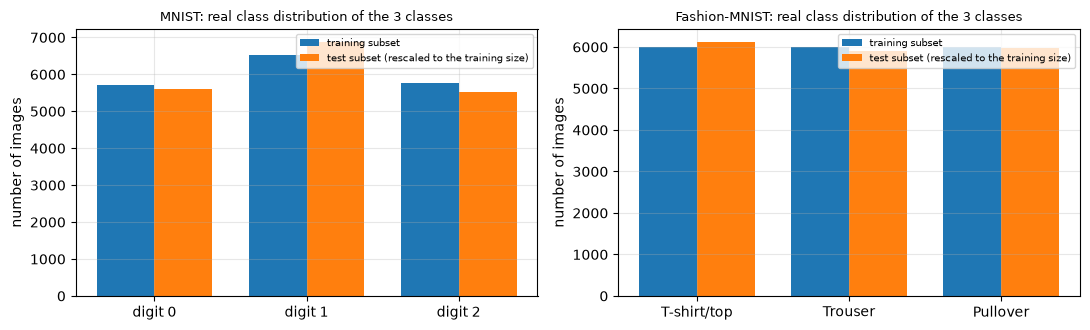

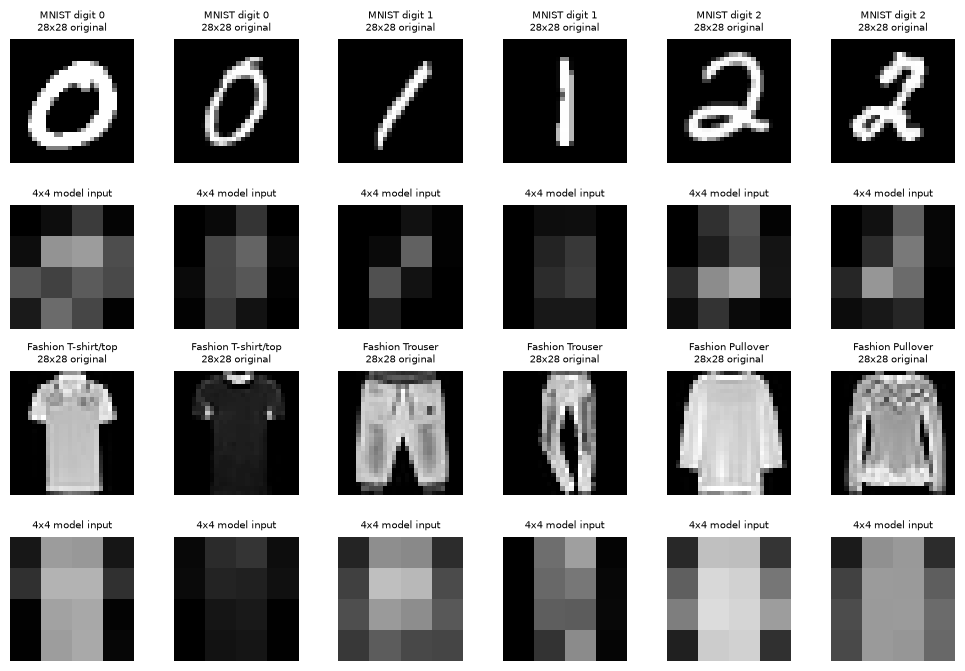

In [5]:
FEATURES = [f"px_{r}_{c}" for r in range(PRE_SIZE // POOL) for c in range(PRE_SIZE // POOL)]
for ds in ["MNIST", "FMNIST"]:
    D = DATA[ds]
    print("=" * 110)
    print(f"{FULL_NAME[ds]}: model input X_train {D['Xtr'].shape} (images x features), X_test {D['Xte'].shape}; raw images {D['raw_tr'].shape[1:]} -> {PRE_SIZE}x{PRE_SIZE} -> {PRE_SIZE // POOL}x{PRE_SIZE // POOL} = {len(FEATURES)} pixel features, values in [{D['Xtr'].min():.2f}, {D['Xtr'].max():.2f}]")
    print("feature names:", FEATURES)
    print("original label values:", sorted(set(D["ytr"].tolist())), "->", CLASS_NAMES[ds], "(the other 7 classes of the official data are not used, as in the paper)")
    cnt = pd.DataFrame({"class": CLASS_NAMES[ds], "official train, this class": D["pool_counts"], f"training subset ({len(D['ytr'])})": np.bincount(D["ytr"], minlength=3),
                        f"test subset ({len(D['yte'])})": np.bincount(D["yte"], minlength=3)}, index=list(CLASSES))
    display(cnt)
    print("mean pixel value %.3f, pixel std %.3f (EPS_UNIT = 0.3081 in the configuration is the standard MNIST pixel std of all 10 digits)" % (D["Xtr"].mean(), D["Xtr"].std()))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, ds in zip(axes, ["MNIST", "FMNIST"]):
    D = DATA[ds]; w = 0.38; xs = np.arange(3)
    ax.bar(xs - w / 2, np.bincount(D["ytr"], minlength=3), w, label="training subset")
    ax.bar(xs + w / 2, np.bincount(D["yte"], minlength=3) * (len(D["ytr"]) / len(D["yte"])), w, label="test subset (rescaled to the training size)")
    ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES[ds]); ax.set_ylabel("number of images"); ax.set_title(f"{FULL_NAME[ds]}: real class distribution of the 3 classes", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 6, figsize=(10, 6.8))
for r_, ds in enumerate(["MNIST", "FMNIST"]):
    D = DATA[ds]
    for c in range(3):
        for j, i in enumerate(np.flatnonzero(D["ytr"] == c)[:2]):
            a = axes[r_ * 2, c * 2 + j]; a.imshow(D["raw_tr"][i], cmap="gray"); a.set_title(f"{FULL_NAME[ds][:7]} {CLASS_NAMES[ds][c]}\n28x28 original", fontsize=7); a.axis("off")
            b = axes[r_ * 2 + 1, c * 2 + j]; b.imshow(D["Xtr"][i].reshape(4, 4), cmap="gray", vmin=0, vmax=1); b.set_title("4x4 model input", fontsize=7); b.axis("off")
plt.tight_layout(); plt.show()

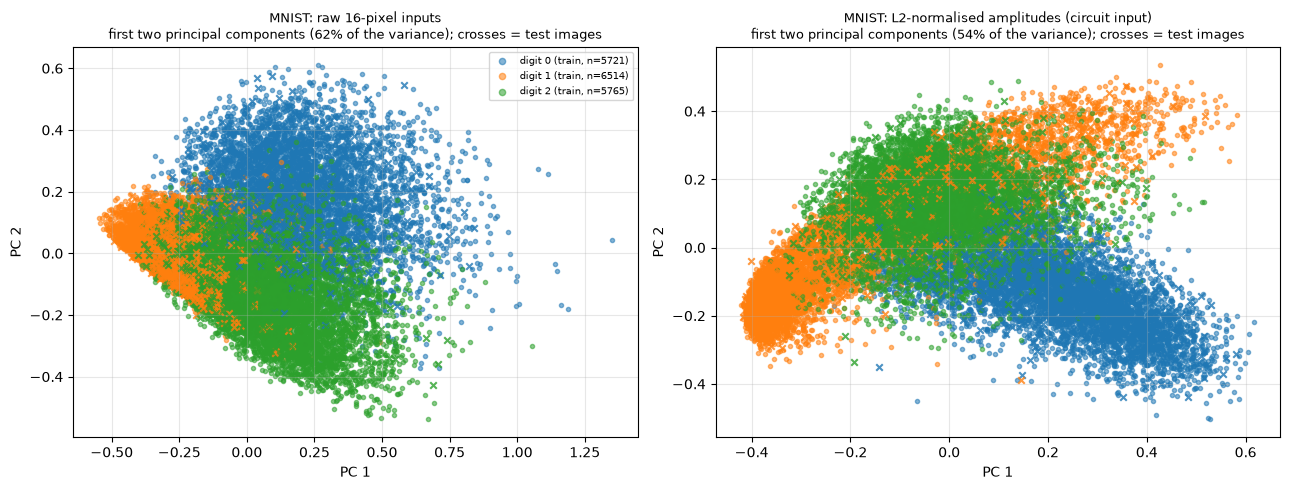

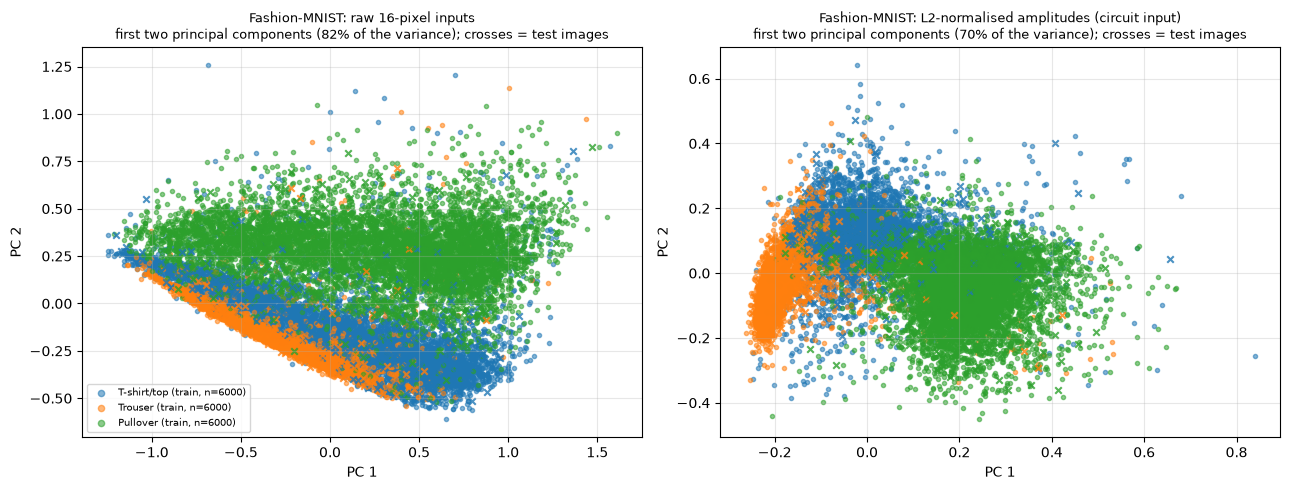

In [6]:
# 2-D scatter of REAL observations coloured by their ground-truth label. PCA is fitted on the training split only; test points are projected (crosses).
# Panel 1: raw 16-pixel inputs.  Panel 2: the same images after the L2 normalisation of the amplitude embedding = the unit vectors the circuit actually receives.
# (The model uses amplitude encoding, not angle encoding, so there is no [0, pi] angle scaling to show.)
cols = ["tab:blue", "tab:orange", "tab:green"]
for ds in ["MNIST", "FMNIST"]:
    D = DATA[ds]; Xn_tr = D["Xtr"] / np.linalg.norm(D["Xtr"], axis=1, keepdims=True); Xn_te = D["Xte"] / np.linalg.norm(D["Xte"], axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (A, B, ttl) in zip(axes, [(D["Xtr"], D["Xte"], "raw 16-pixel inputs"), (Xn_tr, Xn_te, "L2-normalised amplitudes (circuit input)")]):
        pca = PCA(n_components=2, random_state=SEED).fit(A); Ztr, Zte = pca.transform(A), pca.transform(B)
        for c in range(3):
            m = D["ytr"] == c; ax.scatter(Ztr[m, 0], Ztr[m, 1], s=9, color=cols[c], alpha=0.55, label=f"{CLASS_NAMES[ds][c]} (train, n={m.sum()})")
        for c in range(3):
            m = D["yte"] == c; ax.scatter(Zte[m, 0], Zte[m, 1], s=22, marker="x", color=cols[c], alpha=0.8)
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(f"{FULL_NAME[ds]}: {ttl}\nfirst two principal components ({pca.explained_variance_ratio_.sum():.0%} of the variance); crosses = test images", fontsize=9)
    axes[0].legend(fontsize=7, markerscale=1.5)
    plt.tight_layout(); plt.show()

## 2. The quantum model, the attack and the federated protocol

* **Model.** `AmplitudeEmbedding` of the 16 pixels (normalised to unit length) on 4 qubits, two `StronglyEntanglingLayers` (each layer: a general rotation `Rot = RZ RY RZ` on every qubit, then a ring of `CNOT`s whose range grows with the layer), 24 trainable weights,
  and the expectation values of `Z` on qubits 0, 1, 2 as class scores. The reference implementation is a PennyLane QNode. Training needs many thousands of gradient evaluations (15 clients x rounds x PGD), so the same gate list is also written as a tiny **exact NumPy statevector simulator**
  with an **adjoint-differentiation** gradient (mathematically identical to the parameter-shift rule used in the paper) and an analytic input gradient for PGD. The next section asserts that the simulator equals the QNode, and that both gradients are right.
* **Classical twin.** A 16 -> 8 -> 3 tanh MLP with 163 weights that receives exactly the same normalised pixels and is trained with exactly the same federated protocol. It answers whether a finding is a *quantum* property or a property of federated adversarial training.
* **Attack.** White-box untargeted PGD on the 16 pixels in an L-infinity ball, pixels clipped to [0, 1]. The attacker sees the global model.
* **Federated training.** FedAvg over 15 clients; every covered client replaces 50 % of each mini-batch by PGD examples computed against its current local weights.
* **Metrics.** `ara` and `robustness_volume` implement the paper's integrals with the trapezoid rule on the epsilon grid (and on the coverage grid for RV).

In [7]:
# ======================================================================================================
# (a) the reference circuit as a PennyLane QNode: amplitude embedding of 16 pixels on 4 qubits,
#     two StronglyEntanglingLayers (hardware-efficient ansatz, 24 weights), <Z> of qubits 0, 1, 2 = the three class scores
# ======================================================================================================
dev = qml.device("default.qubit", wires=N_QUBITS)
N_CLS = len(CLASSES)

@qml.qnode(dev, interface="numpy")
def qnode(x, w):
    qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), normalize=True)          # CHOICE: amplitude encoding, as in the paper's text
    qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS))                    # CHOICE: the hardware-efficient ansatz (paper: "two layers", not named)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_CLS)]                 # CHOICE: <Z_i> of the first 3 qubits = class scores

W_SHAPE = (N_LAYERS, N_QUBITS, 3)
N_PARAMS = int(np.prod(W_SHAPE))

# ======================================================================================================
# (b) the same circuit as an exact NumPy statevector simulator (fast enough for thousands of gradient evaluations)
#     gate list: StronglyEntanglingLayers = per layer, for every qubit Rot(phi,theta,omega) = RZ(omega) RY(theta) RZ(phi),
#     then CNOT(q, (q + r) mod n) with range r = (layer mod (n-1)) + 1;  wire 0 is the most significant bit of the 16-vector
# ======================================================================================================
DIM = 2 ** N_QUBITS
_IDX = np.arange(DIM)
_BIT = np.stack([(_IDX >> (N_QUBITS - 1 - q)) & 1 for q in range(N_QUBITS)])               # (n, 16)
ZSIGN = 1.0 - 2.0 * _BIT                                                                     # +1 for bit 0, -1 for bit 1
ZM = ZSIGN[:N_CLS]                                                                           # (3, 16): diagonals of Z_0, Z_1, Z_2
_FLIP = [_IDX ^ (1 << (N_QUBITS - 1 - q)) for q in range(N_QUBITS)]

def sel_gate_list(n_layers=N_LAYERS, n=N_QUBITS):
    ops, p = [], 0
    for l in range(n_layers):
        for q in range(n):
            ops += [("rz", q, p), ("ry", q, p + 1), ("rz", q, p + 2)]; p += 3
        r = l % (n - 1) + 1
        ops += [("cx", q, (q + r) % n) for q in range(n)]
    return ops
OPS = sel_gate_list()

def apply_circuit(thetas, psi):
    """thetas: (S, P) one parameter vector per row; psi: (S, 16, B) complex states. Returns the evolved states."""
    for kind, a, b in OPS:
        if kind == "cx":
            perm = _IDX ^ (_BIT[a] << (N_QUBITS - 1 - b))                  # |x> -> |x XOR (x_a << t)>  (an involution)
            psi = psi[:, perm, :]
        else:
            c = np.cos(thetas[:, b] / 2)[:, None]; s = np.sin(thetas[:, b] / 2)[:, None]
            if kind == "rz":                                               # RZ(t) = diag(exp(-it/2), exp(+it/2))
                psi = psi * (c - 1j * s * ZSIGN[a][None, :])[:, :, None]
            else:                                                          # RY(t) = cos(t/2) I - i sin(t/2) Y,  (Y psi)[k] = -i z_k psi[k xor mask]
                psi = c[:, :, None] * psi - (s * ZSIGN[a][None, :])[:, :, None] * psi[:, _FLIP[a], :]
    return psi

_U_CACHE = {"key": None, "U": None}
def unitary(theta):
    """16 x 16 unitary of the ansatz for one flat weight vector (columns = images of the basis states). The last result is cached (PGD calls it many times with the same weights)."""
    key = theta.tobytes()
    if _U_CACHE["key"] != key:
        _U_CACHE["U"] = apply_circuit(theta[None, :], np.eye(DIM, dtype=complex)[None])[0]; _U_CACHE["key"] = key
    return _U_CACHE["U"]

def _gate(kind, a, b, th, psi):
    """One gate with scalar angle th (or none for CNOT) on a batch of states (B, 16)."""
    if kind == "cx": return psi[:, _IDX ^ (_BIT[a] << (N_QUBITS - 1 - b))]
    c, s = np.cos(th / 2), np.sin(th / 2)
    if kind == "rz": return psi * (c - 1j * s * ZSIGN[a])[None, :]
    return c * psi - s * ZSIGN[a][None, :] * psi[:, _FLIP[a]]

def _pauli_apply(kind, a, psi):
    """P psi for the generator of the rotation (Z for RZ, Y for RY)."""
    return ZSIGN[a][None, :] * psi if kind == "rz" else (-1j * ZSIGN[a])[None, :] * psi[:, _FLIP[a]]

def normalise(X):
    n = np.sqrt((X ** 2).sum(1) + 1e-12)
    return X / n[:, None], n

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

class QNNModel:
    """Amplitude-encoded 4-qubit QNN. Gradients: exact parameter-shift rule for the weights, exact analytic gradient for the input."""
    name = "QNN"
    n_params = N_PARAMS
    def init(self, rng): return rng.uniform(0, 2 * np.pi, self.n_params)                      # PennyLane default: uniform on [0, 2 pi)
    def expvals(self, th, X):
        xh, _ = normalise(X); psi = xh.astype(complex) @ unitary(th).T                         # (B, 16)
        return (np.abs(psi) ** 2) @ ZM.T                                                       # (B, 3) values of <Z_i>
    def logits(self, th, X): return LOGIT_SCALE * self.expvals(th, X)
    def loss(self, th, X, y):
        p = softmax(self.logits(th, X)); return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())
    def loss_grad(self, th, X, y):
        """Exact gradient of the mean cross-entropy w.r.t. the 24 weights by adjoint differentiation of the gate list
        (equal to the parameter-shift rule for these gates; checked against it and against finite differences in section 3)."""
        B = len(y); xh, _ = normalise(X); psi = xh.astype(complex); states = []
        for kind, a, b in OPS:                                                      # forward pass, keep the state after every rotation
            psi = _gate(kind, a, b, th[b] if kind != "cx" else None, psi)
            states.append(psi)
        z = (np.abs(psi) ** 2) @ ZM.T; pr = softmax(LOGIT_SCALE * z)
        loss = float(-np.log(pr[np.arange(B), y] + 1e-12).mean())
        dz = LOGIT_SCALE * (pr - np.eye(N_CLS)[y]) / B                              # dL/d<Z_i>
        lam = ((dz @ ZM) * psi)                                                      # O psi_N with O_b = sum_i dz_bi Z_i
        grad = np.zeros(self.n_params)
        for j in range(len(OPS) - 1, -1, -1):                                       # backward pass
            kind, a, b = OPS[j]
            if kind == "cx":
                lam = _gate("cx", a, b, None, lam); continue
            grad[b] = np.imag(np.sum(np.conj(lam) * _pauli_apply(kind, a, states[j])))      # d<O>/d theta_b = Im(lam^H P psi_after)
            lam = _gate(kind, a, b, -th[b], lam)                                    # undo the rotation on the co-state
        return loss, grad
    def loss_grad_shift(self, th, X, y):
        """Reference implementation: parameter-shift rule on the full batch (slow, used only for the check in section 3)."""
        B = len(y); xh, _ = normalise(X)
        P = self.n_params; thetas = np.tile(th, (2 * P + 1, 1))
        thetas[np.arange(P) * 2, np.arange(P)] += np.pi / 2; thetas[np.arange(P) * 2 + 1, np.arange(P)] -= np.pi / 2    # rows 2p, 2p+1 = +/- pi/2 on weight p; last row unshifted
        psi = apply_circuit(thetas, np.broadcast_to(xh.T[None].astype(complex), (2 * P + 1, DIM, B)))
        z = np.einsum("ia,sab->sbi", ZM, np.abs(psi) ** 2)                                     # (S, B, 3)
        pr = softmax(LOGIT_SCALE * z[-1]); oh = np.eye(N_CLS)[y]
        loss = float(-np.log(pr[np.arange(B), y] + 1e-12).mean())
        dz = LOGIT_SCALE * (pr - oh) / B
        dfd = 0.5 * (z[0:2 * P:2] - z[1:2 * P:2])                                              # (P, B, 3)  d<Z_i>/dw_p
        return loss, np.einsum("pbi,bi->p", dfd, dz)
    def input_grad(self, th, X, y):
        """dL_i/dx for every sample (sum of the loss over the batch, so rows are independent): exact, through the normalisation."""
        U = unitary(th); xh, n = normalise(X); psi = xh.astype(complex) @ U.T
        z = (np.abs(psi) ** 2) @ ZM.T; pr = softmax(LOGIT_SCALE * z); dz = LOGIT_SCALE * (pr - np.eye(N_CLS)[y])
        v = (dz @ ZM) * psi                                                                    # (B, 16)   sum_i dz_i * Z_i psi
        g = 2 * np.real(v @ np.conj(U))                                                        # d/d xhat of the loss
        return (g - (g * xh).sum(1, keepdims=True) * xh) / n[:, None]

class MLPModel:
    """Classical twin on IDENTICAL inputs: the same L2 normalisation of the 16 pixels, then 16 -> 8 (tanh) -> 3, soft-max cross-entropy, 163 weights."""
    name = "MLP"
    H = 8
    def __init__(self): self.n_params = 16 * self.H + self.H + self.H * N_CLS + N_CLS
    def init(self, rng):
        s1, s2 = math.sqrt(6 / (16 + self.H)), math.sqrt(6 / (self.H + N_CLS))
        return np.concatenate([rng.uniform(-s1, s1, 16 * self.H), np.zeros(self.H), rng.uniform(-s2, s2, self.H * N_CLS), np.zeros(N_CLS)])
    def _unpack(self, th):
        H = self.H; a = 16 * H
        return th[:a].reshape(16, H), th[a:a + H], th[a + H:a + H + H * N_CLS].reshape(H, N_CLS), th[a + H + H * N_CLS:]
    def _forward(self, th, X):
        W1, b1, W2, b2 = self._unpack(th); xh, n = normalise(X); h = np.tanh(xh @ W1 + b1); return xh, n, h, h @ W2 + b2
    def logits(self, th, X): return self._forward(th, X)[3]
    def loss(self, th, X, y):
        p = softmax(self.logits(th, X)); return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())
    def loss_grad(self, th, X, y):
        W1, b1, W2, b2 = self._unpack(th); xh, n, h, o = self._forward(th, X); B = len(y); p = softmax(o)
        loss = float(-np.log(p[np.arange(B), y] + 1e-12).mean()); do = (p - np.eye(N_CLS)[y]) / B
        dh = (do @ W2.T) * (1 - h ** 2)
        return loss, np.concatenate([(xh.T @ dh).ravel(), dh.sum(0), (h.T @ do).ravel(), do.sum(0)])
    def input_grad(self, th, X, y):
        W1, b1, W2, b2 = self._unpack(th); xh, n, h, o = self._forward(th, X)
        do = softmax(o) - np.eye(N_CLS)[y]; g = ((do @ W2.T) * (1 - h ** 2)) @ W1.T
        return (g - (g * xh).sum(1, keepdims=True) * xh) / n[:, None]

QNN, MLP = QNNModel(), MLPModel()
print("QNN weights:", QNN.n_params, "| MLP weights:", MLP.n_params, "| gate list length:", len(OPS), "(", sum(o[0] != "cx" for o in OPS), "rotations,", sum(o[0] == "cx" for o in OPS), "CNOTs )")

QNN weights: 24 | MLP weights: 163 | gate list length: 32 ( 24 rotations, 8 CNOTs )


In [8]:
# ---------------------------------------------------------------- PGD attack, accuracy, federated training ----------------------------------------------------------------
def pgd(model, th, X, y, eps, steps=None):
    """Untargeted L-infinity PGD on the 16 input pixels (white box); pixels stay in [0, 1]. No random start (CHOICE)."""
    steps = PGD_STEPS if steps is None else steps
    if eps <= 0 or len(X) == 0: return X.copy()
    eps = eps * EPS_UNIT                                              # epsilon is quoted in "standardised pixel" units, see EPS_UNIT in the configuration
    alpha = 2.5 * eps / steps; Xa = X.copy()
    for _ in range(steps):
        Xa = np.clip(np.clip(Xa + alpha * np.sign(model.input_grad(th, Xa, y)), X - eps, X + eps), 0.0, 1.0)
    return Xa

def accuracy(model, th, X, y, eps=0.0):
    Xa = pgd(model, th, X, y, eps) if eps > 0 else X
    return 100.0 * float((model.logits(th, Xa).argmax(1) == y).mean())

def acc_curve(model, th, X, y, eps_grid=None):
    return np.array([accuracy(model, th, X, y, e) for e in (EPS_GRID if eps_grid is None else eps_grid)])

def make_shards(X, y, K, mode, rng):
    """IID: uniform shuffle then K equal shards.  Non-IID: label-sorted, K contiguous shards (near single-class clients)."""
    if mode == "iid":
        idx = np.array_split(rng.permutation(len(y)), K)
    else:
        order = np.lexsort((rng.random(len(y)), y))            # sorted by label, random order inside a label
        idx = np.array_split(order, K)
    return [(X[i], y[i]) for i in idx]

def client_epsilons(gamma, schedule, K, perm):
    """Per-client AT radius (0 = clean). The first round(gamma*K) clients of a fixed random permutation are adversarial; a mix is assigned to them cyclically."""
    n_adv = int(math.floor(gamma * K + 0.5)); eps = np.zeros(K)
    for j, k in enumerate(perm[:n_adv]): eps[k] = schedule[j % len(schedule)]
    return eps

def lr_at(t, rounds):
    """CHOICE: learning rate decays linearly from LR (first round of a training phase) to LR_END_FRAC x LR (last round); every phase (clean, fine-tune, scratch) restarts at LR."""
    return LR * (1.0 - (1.0 - LR_END_FRAC) * t / max(rounds - 1, 1))

def local_update(model, th0, Xc, yc, eps_k, rng, lr):
    th = th0.copy()
    for _ in range(LOCAL_STEPS):
        idx = rng.choice(len(yc), BATCH, replace=len(yc) < BATCH)
        xb, yb = Xc[idx].copy(), yc[idx]
        if eps_k > 0:
            m = int(round(ADV_FRAC * BATCH)); xb[:m] = pgd(model, th, xb[:m], yb[:m], eps_k)      # rho = 50 % of each mini-batch is perturbed
        th -= lr * model.loss_grad(th, xb, yb)[1]
    return th

def fed_train(model, th, shards, rounds, eps_clients, rng, track=None):
    """FedAvg, all K clients every round, uniform average of the K returned weight vectors. track(round, th) is an optional callback."""
    th = th.copy()
    for t in range(rounds):
        lr = lr_at(t, rounds)
        th = np.mean([local_update(model, th, Xc, yc, eps_clients[k], rng, lr) for k, (Xc, yc) in enumerate(shards)], axis=0)
        if track is not None: track(t + 1, th)
    return th

# ---------------------------------------------------------------- the paper's metrics ----------------------------------------------------------------
def ara(acc_percent, eps_grid=None):
    """ARA(gamma) = 1/eps_max * integral_0^eps_max A(gamma, eps)/100 d eps  (trapezoid rule on the epsilon grid)."""
    e = np.array(EPS_GRID if eps_grid is None else eps_grid); return float(trapezoid(np.asarray(acc_percent) / 100.0, e) / e[-1])

def robustness_volume(acc_surface, gammas=None):
    """RV = 1/(eps_max gamma_max) * double integral of A/100 (trapezoid in eps and in gamma). acc_surface: (n_gamma, n_eps), rows ordered like COVERAGES."""
    g = np.array(COVERAGES if gammas is None else gammas); per_gamma = np.array([ara(r) for r in acc_surface])
    return float(trapezoid(per_gamma, g) / g[-1])

_t0 = time.time()
_sh = make_shards(DATA["MNIST"]["Xtr"], DATA["MNIST"]["ytr"], N_CLIENTS, "iid", np.random.default_rng(0))
print("shard sizes", [len(s[1]) for s in _sh][:5], "...  (", N_CLIENTS, "clients )")
print("sanity: ARA of a perfect model =", ara([100] * len(EPS_GRID)), "| RV of a perfect model =", robustness_volume(np.full((len(COVERAGES), len(EPS_GRID)), 100.0)))

shard sizes [1200, 1200, 1200, 1200, 1200] ...  ( 15 clients )
sanity: ARA of a perfect model = 1.0 | RV of a perfect model = 1.0


## Quantum Circuit Architecture

The paper describes its circuit in words only (amplitude embedding on 4 qubits, "two layers of a hardware-efficient ansatz", expectation values mapped to class logits). The circuit that is **actually executed** in this notebook is the PennyLane QNode defined above, drawn here
at template level and at gate level. Assumptions where the paper is silent: the ansatz family (`StronglyEntanglingLayers`), which qubits are measured (the first three, one per class), and the logit scale. The cells then print the qubit count, depth and number of trainable parameters,
and **assert** that the fast NumPy simulator used for training gives the same scores as the drawn QNode on real images, also for adversarial images.

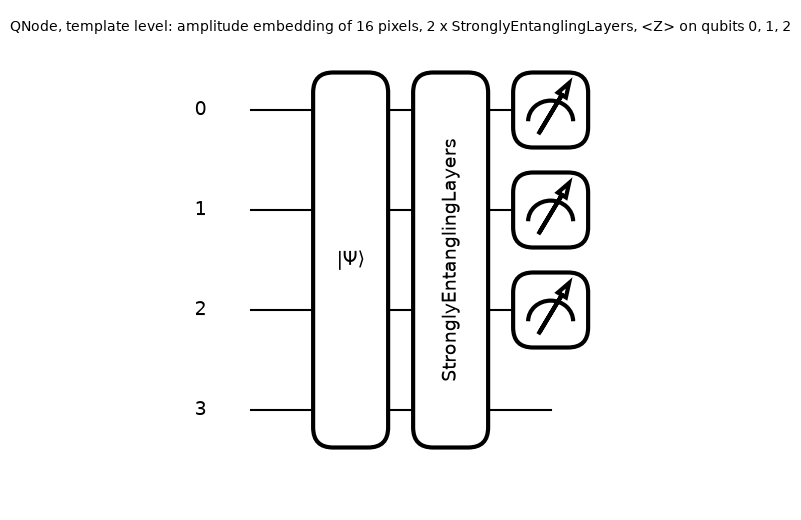

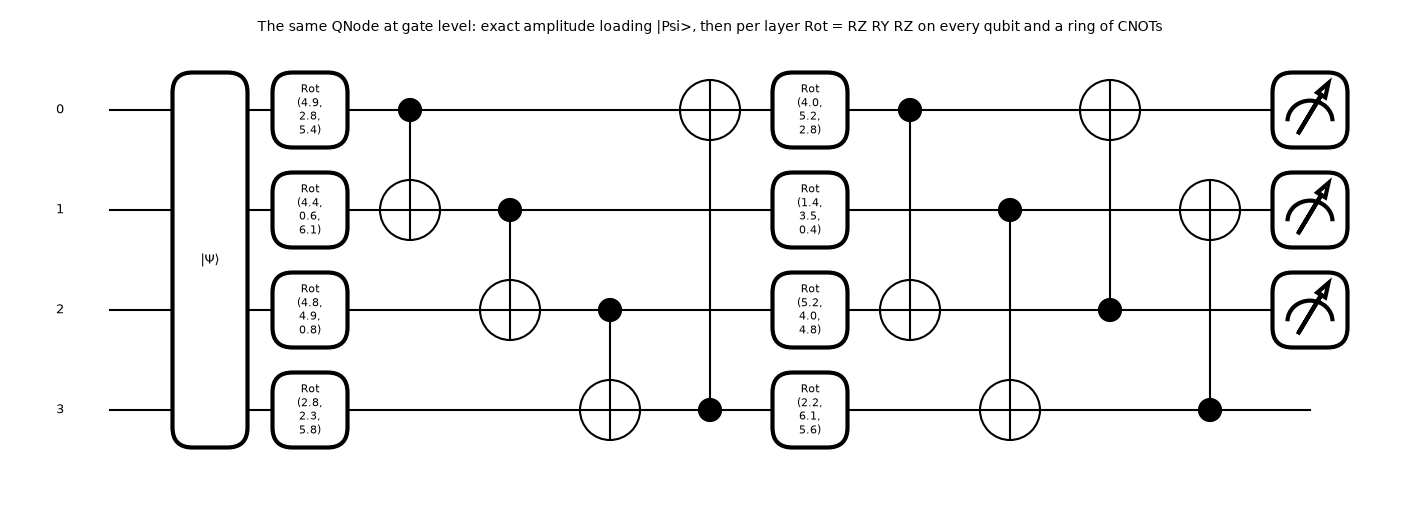

qubits (wires): 4 | circuit depth after decomposition: 9 | gates after decomposition: 17
trainable parameters: 24 = 2 layers x 4 qubits x 3 rotation angles (the 16 input amplitudes are data, not parameters)
depth of the trainable ansatz alone (without the state preparation): 8
measurement: <Z_0>, <Z_1>, <Z_2> (class scores; qubit 3 is not measured), logits = LOGIT_SCALE * <Z>, loss = soft-max cross-entropy


simulator vs PennyLane QNode, <Z_0..2> on 80 real images with random weights: max |difference| = 2.70e-12  (assert < 1e-9: passed)


adversarial images (PGD, epsilon 0.1) give the same scores and the same predictions in the QNode and in the simulator (assert passed)


In [9]:
# The circuit that is executed: draw the real QNode (PennyLane), at template level and at gate level (what the device really runs).
x_demo = DATA["MNIST"]["Xtr"][0]; w_demo = QNN.init(np.random.default_rng(SEED)).reshape(W_SHAPE)
fig, ax = qml.draw_mpl(qnode, level="top", decimals=2)(x_demo, w_demo)
fig.suptitle("QNode, template level: amplitude embedding of 16 pixels, 2 x StronglyEntanglingLayers, <Z> on qubits 0, 1, 2", fontsize=10); plt.show()
fig, ax = qml.draw_mpl(qnode, level="device", decimals=1, fontsize=9)(x_demo, w_demo)
fig.suptitle("The same QNode at gate level: exact amplitude loading |Psi>, then per layer Rot = RZ RY RZ on every qubit and a ring of CNOTs", fontsize=10); plt.show()

sp = qml.specs(qnode, level="device")(x_demo, w_demo)
res = sp.resources
print(f"qubits (wires): {len(dev.wires)} | circuit depth after decomposition: {res.depth} | gates after decomposition: {res.num_gates}")
print(f"trainable parameters: {N_PARAMS} = {N_LAYERS} layers x {N_QUBITS} qubits x 3 rotation angles (the 16 input amplitudes are data, not parameters)")
@qml.qnode(dev)
def _ansatz_only(w):
    qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS)); return qml.expval(qml.PauliZ(0))
print("depth of the trainable ansatz alone (without the state preparation):", qml.specs(_ansatz_only, level="device")(w_demo).resources.depth)
print("measurement: <Z_0>, <Z_1>, <Z_2> (class scores; qubit 3 is not measured), logits = LOGIT_SCALE * <Z>, loss = soft-max cross-entropy")

# ---- the exact NumPy simulator used for training is the SAME circuit: assert it against the QNode on real images, for the weights, and for the adversarial examples ----
rng = np.random.default_rng(SEED); max_dev = 0.0
for ds in ["MNIST", "FMNIST"]:
    Xs = DATA[ds]["Xtr"][:40]; th = QNN.init(rng)
    ref = np.array([qnode(x, th.reshape(W_SHAPE)) for x in Xs])
    max_dev = max(max_dev, float(np.abs(QNN.expvals(th, Xs) - ref).max()))
assert max_dev < 1e-9, max_dev
print(f"simulator vs PennyLane QNode, <Z_0..2> on 80 real images with random weights: max |difference| = {max_dev:.2e}  (assert < 1e-9: passed)")
Xs, ys = DATA["MNIST"]["Xte"][:40], DATA["MNIST"]["yte"][:40]; th = QNN.init(rng)
Xadv = pgd(QNN, th, Xs, ys, 0.1)
ref = np.array([qnode(x, th.reshape(W_SHAPE)) for x in Xadv])
assert np.abs(QNN.expvals(th, Xadv) - ref).max() < 1e-9 and (ref.argmax(1) == QNN.logits(th, Xadv).argmax(1)).all()
print("adversarial images (PGD, epsilon 0.1) give the same scores and the same predictions in the QNode and in the simulator (assert passed)")

### Checks of the training machinery

Three things have to be right before any robustness number can be trusted: the weight gradient (used in training), the input gradient (used by PGD), and the learning rate. The weight gradient is compared with the parameter-shift rule and with finite differences,
the input gradient with finite differences. The learning rate is picked on the held-out **validation** slice (images of the official test split that are not among the reported test images).

In [10]:
# ---- gradient checks: the adjoint gradient used in training = parameter-shift rule = central finite differences; the analytic input gradient used by PGD = finite differences ----
rng = np.random.default_rng(SEED); th = QNN.init(rng); Xg, yg = DATA["MNIST"]["Xtr"][:24], DATA["MNIST"]["ytr"][:24]
l_adj, g_adj = QNN.loss_grad(th, Xg, yg); l_ps, g_ps = QNN.loss_grad_shift(th, Xg, yg)
h = 1e-6; E = np.eye(N_PARAMS)
g_fd = np.array([(QNN.loss(th + h * E[p], Xg, yg) - QNN.loss(th - h * E[p], Xg, yg)) / (2 * h) for p in range(N_PARAMS)])
gx = QNN.input_grad(th, Xg, yg); gx_fd = np.zeros_like(Xg)
for i in range(len(yg)):
    for j in range(Xg.shape[1]):
        d = np.zeros(Xg.shape[1]); d[j] = h
        gx_fd[i, j] = (QNN.loss(th, (Xg[i] + d)[None], yg[i:i + 1]) - QNN.loss(th, (Xg[i] - d)[None], yg[i:i + 1])) / (2 * h)
print(f"weight gradient: adjoint vs parameter-shift {np.abs(g_adj - g_ps).max():.1e}, adjoint vs finite differences {np.abs(g_adj - g_fd).max():.1e}")
print(f"input gradient (used by PGD): analytic vs finite differences {np.abs(gx - gx_fd).max():.1e}")
assert np.abs(g_adj - g_ps).max() < 1e-9 and np.abs(g_adj - g_fd).max() < 1e-6 and np.abs(gx - gx_fd).max() < 1e-6
Xm, ym = DATA["MNIST"]["Xtr"][:24], DATA["MNIST"]["ytr"][:24]; thm = MLP.init(rng)
gm_fd = np.array([[(MLP.loss(thm, (Xm[i] + e * np.eye(16)[j])[None], ym[i:i + 1]) - MLP.loss(thm, (Xm[i] - e * np.eye(16)[j])[None], ym[i:i + 1])) / (2 * e) for j in range(16)] for i in range(4) for e in [1e-6]])
assert np.abs(MLP.input_grad(thm, Xm[:4], ym[:4]) - gm_fd).max() < 1e-6
print("classical MLP twin: input gradient checked against finite differences as well")

# ---- learning-rate check on the VALIDATION slice (official test-split images that are not among the reported test images): 5 clean federated rounds, IID MNIST ----
Dv = DATA["MNIST"]; sh = make_shards(Dv["Xtr"], Dv["ytr"], N_CLIENTS, "iid", np.random.default_rng(1)); rows = []
LR_SAVED = LR
for lr_try in (0.1, 0.25, 0.5, 1.0):
    LR = lr_try; r = np.random.default_rng(1); th_ = fed_train(QNN, QNN.init(r), sh, 5, np.zeros(N_CLIENTS), r)
    rows.append((lr_try, accuracy(QNN, th_, Dv["Xval"], Dv["yval"])))
LR = LR_SAVED
print(pd.DataFrame(rows, columns=["learning rate", "validation accuracy % after 5 rounds"]).round(1).to_string(index=False), f"\n-> best learning rate of this grid on the validation slice: {max(rows, key=lambda r: r[1])[0]}; LR in the configuration cell: {LR}")

weight gradient: adjoint vs parameter-shift 2.5e-16, adjoint vs finite differences 2.9e-10
input gradient (used by PGD): analytic vs finite differences 9.9e-10
classical MLP twin: input gradient checked against finite differences as well


 learning rate  validation accuracy % after 5 rounds
           0.1                                  58.1
           0.2                                  69.7
           0.5                                  80.4
           1.0                                  84.2 
-> best learning rate of this grid on the validation slice: 1.0; LR in the configuration cell: 1.0


## 3. Experiment machinery

Every federated run (a model, a dataset, a split, fine-tune or scratch, a schedule, a coverage and a seed) is cached in a dictionary so that cells can be re-run cheaply.
The clean reference model of each (dataset, split, seed) is trained once and shared by all fine-tune runs, as in the paper; the 0 % coverage run is shared by all schedules. All clients take part in every round.

In [11]:
# ---------------------------------------------------------------- experiment bookkeeping: every run is cached in RES so cells can be re-run cheaply ----------------------------------------------------------------
SCHEDULES = {"fixed 0.1": [0.1], "fixed 0.3": [0.3], "mix [0.01,0.02,0.05]": [0.01, 0.02, 0.05], "mix [0.1,0.15,0.2]": [0.1, 0.15, 0.2], "mix [0.3,0.4,0.5]": [0.3, 0.4, 0.5]}
SCHED_IDX = {k: i for i, k in enumerate(SCHEDULES)}
DS_IDX, SPLIT_IDX, MODE_IDX = {"MNIST": 0, "FMNIST": 1}, {"iid": 0, "noniid": 1}, {"finetune": 0, "scratch": 1}
RES, BASE, SETUPS, TIMES = {}, {}, {}, {}

def exp_rng(*ids): return np.random.default_rng([SEED, *ids])

def get_setup(ds, split, seed):
    key = (ds, split, seed)
    if key not in SETUPS:
        r = exp_rng(DS_IDX[ds], SPLIT_IDX[split], seed, 0)
        shards = make_shards(DATA[ds]["Xtr"], DATA[ds]["ytr"], N_CLIENTS, split, r)
        SETUPS[key] = dict(shards=shards, perm=r.permutation(N_CLIENTS))        # same random client order for every gamma / schedule of this (dataset, split, seed)
    return SETUPS[key]

def get_base(model, ds, split, seed):
    """Clean federated training from a random initialisation (CLEAN_ROUNDS rounds). Returns (theta0, theta_clean, history of validation accuracy per round)."""
    key = (model.name, ds, split, seed)
    if key not in BASE:
        t0 = time.time(); S = get_setup(ds, split, seed)
        th0 = model.init(exp_rng(DS_IDX[ds], SPLIT_IDX[split], seed, 1)); hist = [accuracy(model, th0, DATA[ds]["Xval"], DATA[ds]["yval"])]
        th = fed_train(model, th0, S["shards"], CLEAN_ROUNDS, np.zeros(N_CLIENTS), exp_rng(DS_IDX[ds], SPLIT_IDX[split], seed, 2),
                       track=lambda t, w: hist.append(accuracy(model, w, DATA[ds]["Xval"], DATA[ds]["yval"])))
        BASE[key] = (th0, th, np.array(hist)); TIMES[key] = time.time() - t0
    return BASE[key]

def run(model, ds, split, mode, sched, gamma, seed=0):
    """One federated run + its accuracy-vs-epsilon curve on the test set. mode: 'finetune' (warm start from the clean model, FT_ROUNDS) or 'scratch' (random init, SCRATCH_ROUNDS)."""
    key = (model.name, ds, split, mode, sched if gamma > 0 else "-", float(gamma), seed)
    if key in RES: return RES[key]
    t0 = time.time(); S = get_setup(ds, split, seed); th0, thb, _ = get_base(model, ds, split, seed)
    eps_cl = client_epsilons(gamma, SCHEDULES[sched], N_CLIENTS, S["perm"]) if gamma > 0 else np.zeros(N_CLIENTS)
    r = exp_rng(DS_IDX[ds], SPLIT_IDX[split], seed, 10 + MODE_IDX[mode], int(round(gamma * 100)), SCHED_IDX.get(sched, 9) if gamma > 0 else 9)
    th = fed_train(model, thb if mode == "finetune" else th0, S["shards"], FT_ROUNDS if mode == "finetune" else SCRATCH_ROUNDS, eps_cl, r)
    RES[key] = acc_curve(model, th, DATA[ds]["Xte"], DATA[ds]["yte"]); TIMES[key] = time.time() - t0
    return RES[key]

def surface(model, ds, split, mode, sched, seed=0):
    return np.array([run(model, ds, split, mode, sched, g, seed) for g in COVERAGES])

def show_surface(S, title=""):
    df = pd.DataFrame(S, index=[f"{int(g*100)} %" for g in COVERAGES], columns=[f"{e:g}" for e in EPS_GRID]).round(1)
    df["ARA"] = [round(ara(r), 4) for r in S]; df.index.name = "coverage"; return df

def central_train(model, th0, X, y, steps, rng, batch):
    th = th0.copy()
    for s in range(steps):
        idx = rng.choice(len(y), batch, replace=False); th -= lr_at(s, steps) * model.loss_grad(th, X[idx], y[idx])[1]
    return th

## 4. Centralised vs federated under attack (paper Table I)

The first claim of the paper: federation alone brings no robustness. One quantum network is trained centrally and one is trained with FedAvg on 15 IID shards (the clean reference model that all later fine-tuning starts from), and both are attacked with PGD.
The classical federated MLP and two classical scikit-learn models (RandomForest, RBF-SVC, which are not differentiable here, so they receive *transferred* PGD examples crafted against the QFL model) are added for context.

**Note on calibration.** The pixel unit of epsilon is the one constant fitted to the paper (section 10, EPS_UNIT), using this QFL row. The clean accuracy and the *shape* of the curve are therefore partly by construction; what is a real test is the second row (centralised vs federated), Tables II-IV and the coverage experiments.

,eps=0,eps=0.01,eps=0.05,eps=0.1,eps=0.2,eps=0.3,eps=0.5,ARA
paper: Centralized,80.6,75.9,58.2,32.9,0.2,0.0,0.0,0.1481
paper: QFL,79.5,75.4,59.6,24.7,0.0,0.0,0.0,0.1363
QFL (this notebook),84.7,80.4,52.9,22.7,3.5,0.2,0.0,0.1379
Centralized (this notebook),87.2,82.8,55.4,24.0,3.6,0.1,0.0,0.1435
classical FedAvg MLP (white-box),92.0,89.3,56.4,29.6,8.0,0.7,0.0,0.1671


,eps=0,eps=0.01,eps=0.05,eps=0.1,eps=0.2,eps=0.3,eps=0.5
model,,,,,,,
RandomForest (transfer from QFL-PGD),98.4,74.7,52.1,36.8,21.2,12.2,6.2
SVC (rbf) (transfer from QFL-PGD),97.7,96.3,71.9,37.3,17.7,13.9,12.8


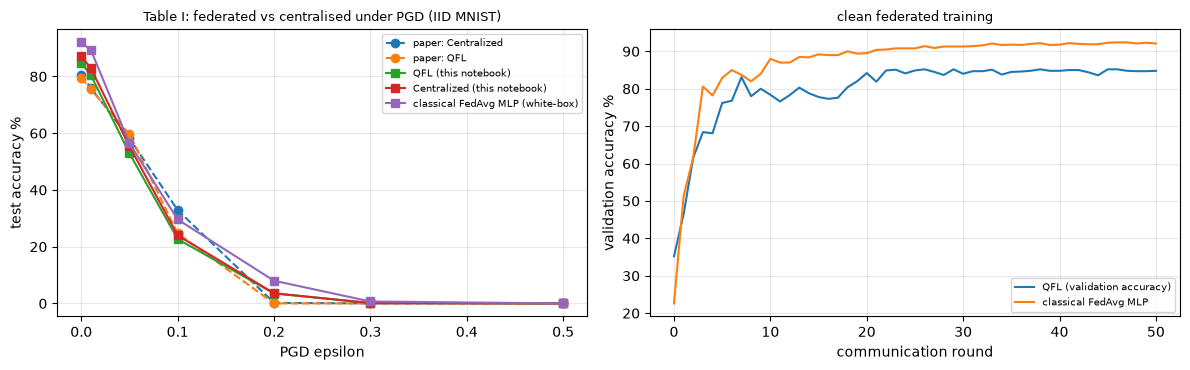

[153 s]  clean QFL accuracy 84.7 % (paper 79.5), centralised 87.2 % (paper 80.6); test set of 1000 images -> 1-sigma binomial error about 1.3 points


In [12]:
PAPER_T1 = {"Centralized": [80.6, 75.9, 58.2, 32.9, 0.2, 0.0, 0.0], "QFL": [79.5, 75.4, 59.6, 24.7, 0.0, 0.0, 0.0]}      # paper, Table I (epsilon = 0, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5)
ds = "MNIST"; D = DATA[ds]; t0 = time.time()

# --- QFL: clean federated training (the paper's "reference QFL model": CLEAN_ROUNDS rounds of FedAvg on IID shards) ---
th0, th_qfl, hist = get_base(QNN, ds, "iid", 0)
T1 = {"QFL (this notebook)": acc_curve(QNN, th_qfl, D["Xte"], D["yte"])}
# --- centralised: ONE quantum network trained on all training images with the same total amount of gradient work ---
# CHOICE: same weight initialisation, mini-batch = BATCH x N_CLIENTS images, CLEAN_ROUNDS x LOCAL_STEPS steps (one federated round with IID clients ~ one such step per local step)
th_cen = central_train(QNN, th0, D["Xtr"], D["ytr"], CLEAN_ROUNDS * LOCAL_STEPS, exp_rng(0, 0, 0, 3), BATCH * N_CLIENTS)
T1["Centralized (this notebook)"] = acc_curve(QNN, th_cen, D["Xte"], D["yte"])
# --- classical federated twin on the identical 16 inputs (same FedAvg protocol, white-box PGD) ---
_, th_mlp, hist_mlp = get_base(MLP, ds, "iid", 0)
T1["classical FedAvg MLP (white-box)"] = acc_curve(MLP, th_mlp, D["Xte"], D["yte"])
T1_df = pd.DataFrame({**{f"paper: {k}": v for k, v in PAPER_T1.items()}, **T1}, index=[f"eps={e:g}" for e in EPS_GRID]).T.round(1)
T1_df["ARA"] = [round(ara(r), 4) for r in T1_df.values[:, :len(EPS_GRID)].astype(float)]
display(T1_df)

# --- classical models on the same inputs (L2-normalised pixels): clean accuracy and black-box transfer of the PGD examples crafted against the QFL model ---
Xn_tr, _ = normalise(D["Xtr"]); rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(Xn_tr, D["ytr"]); svc = SVC(kernel="rbf", C=1.0, random_state=SEED).fit(Xn_tr, D["ytr"])
rows = []
for nm, clf in [("RandomForest", rf), ("SVC (rbf)", svc)]:
    accs = []
    for e in EPS_GRID:
        Xa = pgd(QNN, th_qfl, D["Xte"], D["yte"], e) if e > 0 else D["Xte"]       # examples crafted against the QFL model, evaluated on the classical model (transfer)
        accs.append(100 * float((clf.predict(normalise(Xa)[0]) == D["yte"]).mean()))
    rows.append((nm + " (transfer from QFL-PGD)", *np.round(accs, 1)))
display(pd.DataFrame(rows, columns=["model"] + [f"eps={e:g}" for e in EPS_GRID]).set_index("model"))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, v in PAPER_T1.items(): ax[0].plot(EPS_GRID, v, "o--", label=f"paper: {k}")
for k, v in T1.items(): ax[0].plot(EPS_GRID, v, "s-", label=k)
ax[0].set_xlabel("PGD epsilon"); ax[0].set_ylabel("test accuracy %"); ax[0].set_title("Table I: federated vs centralised under PGD (IID MNIST)", fontsize=9); ax[0].legend(fontsize=7)
ax[1].plot(hist, label="QFL (validation accuracy)"); ax[1].plot(hist_mlp, label="classical FedAvg MLP"); ax[1].set_xlabel("communication round"); ax[1].set_ylabel("validation accuracy %"); ax[1].set_title("clean federated training", fontsize=9); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"[{time.time() - t0:.0f} s]  clean QFL accuracy {T1['QFL (this notebook)'][0]:.1f} % (paper 79.5), centralised {T1['Centralized (this notebook)'][0]:.1f} % (paper 80.6); test set of {len(D['yte'])} images -> 1-sigma binomial error about {100 * np.sqrt(0.8 * 0.2 / len(D['yte'])):.1f} points")

## 5. Fine-tune vs scratch adversarial training at epsilon = 0.1 (paper Fig. 2 and Table II)

*Fine-tune*: take the clean federated model and continue for `FT_ROUNDS` rounds with the adversarial clients training at epsilon = 0.1. *Scratch*: start from the same random weights as the clean model and train `SCRATCH_ROUNDS` rounds with adversarial training from the first round.
Coverage gamma is swept over 0, 20, 50, 75, 100 % of the 15 clients (0, 3, 8, 11, 15 clients). The heat maps show test accuracy under PGD for every (gamma, epsilon); Table II condenses each heat map into the Robustness Volume (RV) and the mean ARA.

fine-tune sweep done in 234 s


scratch sweep done in 176 s

Fine-tune (clean model, then 30 rounds with AT at eps = 0.1), accuracy % under PGD:


,0,0.01,0.05,0.1,0.2,0.3,0.5,ARA
coverage,,,,,,,,
0 %,84.5,80.1,52.9,22.3,3.6,0.2,0.0,0.1374
20 %,83.9,80.4,56.2,24.1,3.8,0.2,0.0,0.1435
50 %,83.1,79.7,59.7,32.2,3.7,0.2,0.0,0.1582
75 %,83.4,79.8,62.0,34.9,4.1,0.1,0.0,0.1649
100 %,85.0,81.2,63.0,37.2,4.9,0.1,0.0,0.1717


Scratch (random initialisation, 20 rounds with AT at eps = 0.1), accuracy % under PGD:


,0,0.01,0.05,0.1,0.2,0.3,0.5,ARA
coverage,,,,,,,,
0 %,86.9,83.3,56.0,21.4,2.9,0.1,0.0,0.1389
20 %,84.8,79.5,49.4,20.1,5.8,0.4,0.0,0.1356
50 %,82.3,78.3,50.0,22.6,9.4,1.5,0.0,0.1496
75 %,85.4,82.1,64.3,34.2,4.4,0.4,0.0,0.1688
100 %,78.6,74.8,53.7,19.9,0.5,0.0,0.0,0.1244


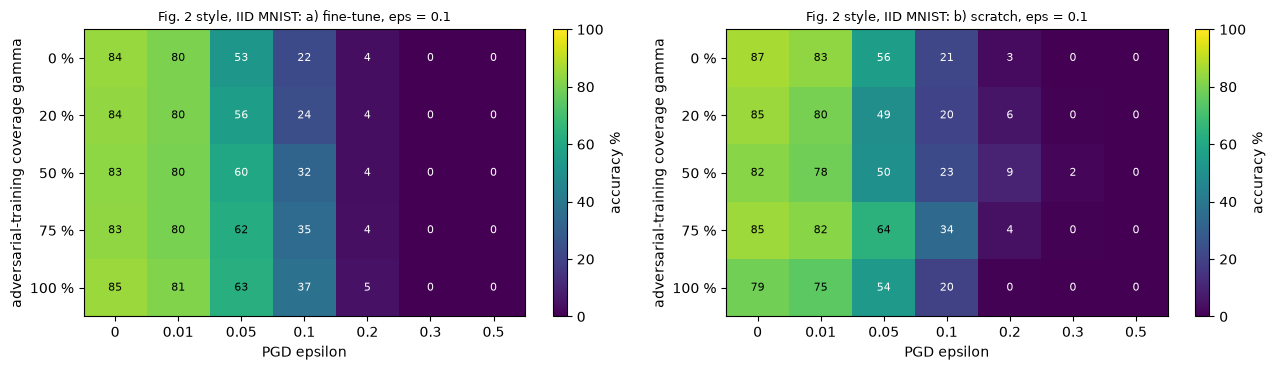

,RV (here),ARA mean (here),RV (paper),ARA mean (paper)
experiment,,,,
Fine-tune eps=0.1,0.1558,0.1551,0.1513,0.1507
Scratch eps=0.1,0.1467,0.1435,0.1443,0.1462


In [13]:
PAPER_T2 = {"Fine-tune eps=0.1": (0.151307, 0.150746), "Scratch eps=0.1": (0.144324, 0.146190)}      # paper, Table II: (Robustness Volume, ARA mean)
t0 = time.time(); ds, split = "MNIST", "iid"
S_ft = surface(QNN, ds, split, "finetune", "fixed 0.1")
print(f"fine-tune sweep done in {time.time() - t0:.0f} s"); t1 = time.time()
S_sc = surface(QNN, ds, split, "scratch", "fixed 0.1") if RUN_SCRATCH else None
if RUN_SCRATCH: print(f"scratch sweep done in {time.time() - t1:.0f} s")
print("\nFine-tune (clean model, then", FT_ROUNDS, "rounds with AT at eps = 0.1), accuracy % under PGD:"); display(show_surface(S_ft))
if RUN_SCRATCH: print("Scratch (random initialisation,", SCRATCH_ROUNDS, "rounds with AT at eps = 0.1), accuracy % under PGD:"); display(show_surface(S_sc))

fig, axes = plt.subplots(1, 2 if RUN_SCRATCH else 1, figsize=(13 if RUN_SCRATCH else 6.5, 3.8), squeeze=False)
for ax, S, ttl in zip(axes[0], [S_ft, S_sc], ["a) fine-tune, eps = 0.1", "b) scratch, eps = 0.1"]):
    if S is None: continue
    im = ax.imshow(S, cmap="viridis", vmin=0, vmax=100, aspect="auto"); ax.set_xticks(range(len(EPS_GRID))); ax.set_xticklabels([f"{e:g}" for e in EPS_GRID]); ax.set_yticks(range(len(COVERAGES))); ax.set_yticklabels([f"{int(g * 100)} %" for g in COVERAGES])
    for i in range(S.shape[0]):
        for j in range(S.shape[1]): ax.text(j, i, f"{S[i, j]:.0f}", ha="center", va="center", color="w" if S[i, j] < 60 else "k", fontsize=8)
    ax.set_xlabel("PGD epsilon"); ax.set_ylabel("adversarial-training coverage gamma"); ax.set_title(f"Fig. 2 style, IID MNIST: {ttl}", fontsize=9); ax.grid(False); plt.colorbar(im, ax=ax, label="accuracy %")
plt.tight_layout(); plt.show()

rows = [("Fine-tune eps=0.1", robustness_volume(S_ft), float(np.mean([ara(r) for r in S_ft])))]
if RUN_SCRATCH: rows.append(("Scratch eps=0.1", robustness_volume(S_sc), float(np.mean([ara(r) for r in S_sc]))))
T2 = pd.DataFrame(rows, columns=["experiment", "RV (here)", "ARA mean (here)"]).set_index("experiment")
T2["RV (paper)"] = [PAPER_T2[k][0] for k in T2.index]; T2["ARA mean (paper)"] = [PAPER_T2[k][1] for k in T2.index]
display(T2.round(4))

## 6. Epsilon schedules: fixed radii and mixes (paper Fig. 3 and Table III)

Five schedules are compared at every coverage, all fine-tuned: fixed 0.1, fixed 0.3, and cyclic mixes of low [0.01, 0.02, 0.05], moderate [0.10, 0.15, 0.20] and strong [0.3, 0.4, 0.5] radii that are handed to the adversarial clients one after the other.
(`FAST_MODE` runs only fixed 0.1 and the moderate mix.)

5 schedules x 4 coverages (+ the shared 0 % run) finished in 681 s
Table III re-computed here (RV, ARA mean, ARA at each coverage):


,RV,ARA mean,ARA 0%,ARA 20%,ARA 50%,ARA 75%,ARA 100%
fixed 0.1,0.1558,0.1551,0.1374,0.1435,0.1582,0.1649,0.1717
fixed 0.3,0.1378,0.1339,0.1374,0.1493,0.1440,0.1378,0.1014
"mix [0.01,0.02,0.05]",0.1410,0.1409,0.1374,0.1382,0.1421,0.1425,0.1442
"mix [0.1,0.15,0.2]",0.1586,0.1568,0.1374,0.1478,0.1646,0.1668,0.1673
"mix [0.3,0.4,0.5]",0.1256,0.1200,0.1374,0.1469,0.1405,0.1165,0.0588


Table III of the paper for the same schedules:


,RV,ARA mean,ARA 0%,ARA 20%,ARA 50%,ARA 75%,ARA 100%
fixed 0.1,0.1513,0.1507,0.1363,0.1502,0.1495,0.1544,0.1633
fixed 0.3,0.1483,0.1480,0.1363,0.1423,0.1523,0.1490,0.1600
"mix [0.01,0.02,0.05]",0.1423,0.1412,0.1363,0.1438,0.1440,0.1427,0.1391
"mix [0.1,0.15,0.2]",0.1531,0.1523,0.1363,0.1461,0.1523,0.1615,0.1655
"mix [0.3,0.4,0.5]",0.1454,0.1475,0.1363,0.1450,0.1514,0.1265,0.1785


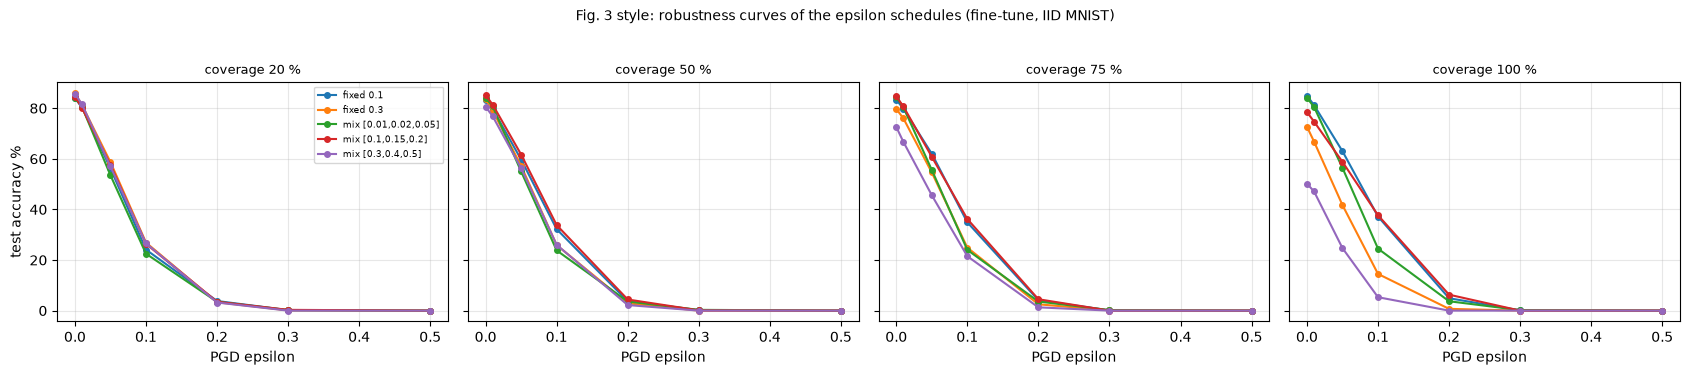

In [14]:
# paper, Table III: RV, ARA mean and ARA(gamma) for the five schedules (fine-tune, IID MNIST)
PAPER_T3 = pd.DataFrame({
    "fixed 0.1":            [0.151307, 0.150746, 0.13634, 0.15016, 0.14949, 0.15445, 0.16329],
    "fixed 0.3":            [0.148319, 0.147972, 0.13634, 0.14227, 0.15228, 0.14895, 0.16002],
    "mix [0.01,0.02,0.05]": [0.142268, 0.141202, 0.13634, 0.14385, 0.14400, 0.14275, 0.13907],
    "mix [0.1,0.15,0.2]":   [0.153087, 0.152338, 0.13634, 0.14605, 0.15230, 0.16146, 0.16554],
    "mix [0.3,0.4,0.5]":    [0.145448, 0.147544, 0.13634, 0.14501, 0.15137, 0.12648, 0.17852]},
    index=["RV", "ARA mean", "ARA 0%", "ARA 20%", "ARA 50%", "ARA 75%", "ARA 100%"])
t0 = time.time(); ds, split = "MNIST", "iid"
SURF = {s: surface(QNN, ds, split, "finetune", s) for s in SCHEDULE_NAMES}
print(f"{len(SCHEDULE_NAMES)} schedules x {len(COVERAGES) - 1} coverages (+ the shared 0 % run) finished in {time.time() - t0:.0f} s")

rows = {}
for s, S in SURF.items():
    ar = [ara(r) for r in S]; rows[s] = [robustness_volume(S), float(np.mean(ar))] + ar
T3 = pd.DataFrame(rows, index=PAPER_T3.index).T
T3_paper = PAPER_T3[list(SURF)].T
print("Table III re-computed here (RV, ARA mean, ARA at each coverage):"); display(T3.round(4))
print("Table III of the paper for the same schedules:"); display(T3_paper.round(4))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, gi in zip(axes, [1, 2, 3, 4]):
    for s, S in SURF.items(): ax.plot(EPS_GRID, S[gi], "o-", label=s, ms=4)
    ax.set_title(f"coverage {int(COVERAGES[gi] * 100)} %", fontsize=9); ax.set_xlabel("PGD epsilon")
axes[0].set_ylabel("test accuracy %"); axes[0].legend(fontsize=6.5)
plt.suptitle("Fig. 3 style: robustness curves of the epsilon schedules (fine-tune, IID MNIST)", y=1.03, fontsize=10); plt.tight_layout(); plt.show()

## 7. Non-IID data and Fashion-MNIST (paper Fig. 4 and Table IV)

In the label-sorted split the training images are ordered by class and cut into 15 contiguous shards, so almost every client sees a single class. The paper reports that this halves the Robustness Volume. The experiment (fine-tune, epsilon = 0.1, all coverages) is run for IID and sorted
splits of both datasets.

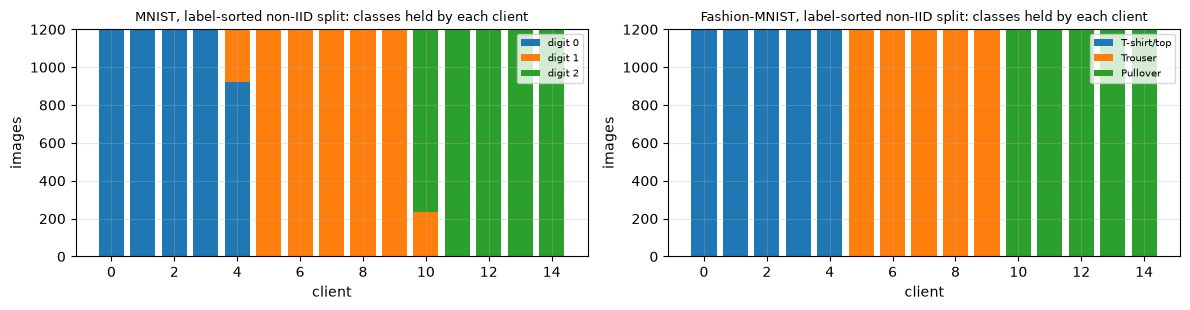

MNIST iid: done (4 s elapsed); clean-trained model accuracy 84.8 % on the validation slice


MNIST noniid: done (444 s elapsed); clean-trained model accuracy 74.1 % on the validation slice


Fashion-MNIST iid: done (701 s elapsed); clean-trained model accuracy 90.3 % on the validation slice


Fashion-MNIST noniid: done (852 s elapsed); clean-trained model accuracy 81.2 % on the validation slice


,RV here,ARA mean here,RV paper,ARA mean paper,clean acc % (0 % coverage),clean acc % (100 % coverage)
experiment,,,,,,
IID MNIST,0.156,0.155,0.151,0.151,84.5,85.0
Non-IID (sorted) MNIST,0.098,0.100,0.077,0.079,78.9,73.1
IID Fashion-MNIST,0.233,0.233,0.154,0.155,89.8,90.4
Non-IID (sorted) Fashion-MNIST,0.165,0.159,0.062,0.066,63.9,86.9


MNIST: RV falls from 0.156 (IID) to 0.098 (sorted non-IID): -37 %   (paper: -49 %)
Fashion-MNIST: RV falls from 0.233 (IID) to 0.165 (sorted non-IID): -29 %   (paper: -60 %)


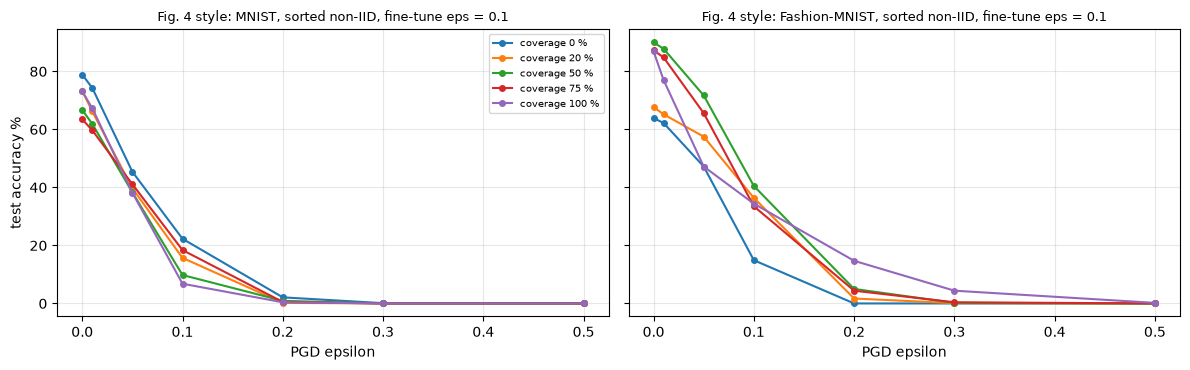

In [15]:
PAPER_T4 = {("MNIST", "iid"): (0.151, 0.151), ("MNIST", "noniid"): (0.077, 0.079), ("FMNIST", "iid"): (0.154, 0.155), ("FMNIST", "noniid"): (0.062, 0.066)}   # paper, Table IV: (RV, ARA mean), eps = 0.1 fine-tune
t0 = time.time()
# what a label-sorted split looks like: class composition of each of the 15 clients
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, ds in zip(axes, ["MNIST", "FMNIST"]):
    sh_ = get_setup(ds, "noniid", 0)["shards"]; comp = np.array([np.bincount(y_, minlength=3) for _, y_ in sh_])
    bottom = np.zeros(N_CLIENTS)
    for c in range(3): ax.bar(range(N_CLIENTS), comp[:, c], bottom=bottom, color=cols[c], label=CLASS_NAMES[ds][c]); bottom += comp[:, c]
    ax.set_xlabel("client"); ax.set_ylabel("images"); ax.set_title(f"{FULL_NAME[ds]}, label-sorted non-IID split: classes held by each client", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

CASES = [("MNIST", "iid"), ("MNIST", "noniid"), ("FMNIST", "iid"), ("FMNIST", "noniid")] if RUN_OTHER_DATASETS else [("MNIST", "iid")]
SURF4 = {}
for ds, split in CASES:
    SURF4[(ds, split)] = surface(QNN, ds, split, "finetune", "fixed 0.1")
    print(f"{FULL_NAME[ds]} {split}: done ({time.time() - t0:.0f} s elapsed); clean-trained model accuracy {BASE[('QNN', ds, split, 0)][2][-1]:.1f} % on the validation slice")
rows = []
for (ds, split), S in SURF4.items():
    rv, am = robustness_volume(S), float(np.mean([ara(r) for r in S])); prv, pam = PAPER_T4[(ds, split)]
    rows.append((f"{'IID' if split == 'iid' else 'Non-IID (sorted)'} {FULL_NAME[ds]}", round(rv, 3), round(am, 3), prv, pam, round(S[0, 0], 1), round(S[-1, 0], 1)))
T4 = pd.DataFrame(rows, columns=["experiment", "RV here", "ARA mean here", "RV paper", "ARA mean paper", "clean acc % (0 % coverage)", "clean acc % (100 % coverage)"]).set_index("experiment")
display(T4)
for ds in ["MNIST", "FMNIST"]:
    if (ds, "noniid") in SURF4:
        a, b = T4.loc[f"IID {FULL_NAME[ds]}", "RV here"], T4.loc[f"Non-IID (sorted) {FULL_NAME[ds]}", "RV here"]
        print(f"{FULL_NAME[ds]}: RV falls from {a:.3f} (IID) to {b:.3f} (sorted non-IID): {100 * (b / a - 1):+.0f} %   (paper: {'-49' if ds == 'MNIST' else '-60'} %)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, ds in zip(axes, ["MNIST", "FMNIST"]):
    if (ds, "noniid") not in SURF4: continue
    for gi, g in enumerate(COVERAGES): ax.plot(EPS_GRID, SURF4[(ds, "noniid")][gi], "o-", ms=4, label=f"coverage {int(g * 100)} %")
    ax.set_xlabel("PGD epsilon"); ax.set_title(f"Fig. 4 style: {FULL_NAME[ds]}, sorted non-IID, fine-tune eps = 0.1", fontsize=9)
axes[0].set_ylabel("test accuracy %"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 8. A classical federated twin (not in the paper)

Is the interplay of coverage and non-IID data specific to quantum models? The classical MLP is trained with the identical federated adversarial-training protocol on the identical inputs (IID and sorted MNIST, fine-tune, epsilon = 0.1).

classical twin done in 102 s


,model,split,clean acc % (gamma=0),acc % at eps=0.1 (gamma=0),acc % at eps=0.1 (gamma=100 %),RV
0,classical MLP,iid,92.7,28.8,48.8,0.205
1,quantum QNN,iid,84.5,22.3,37.2,0.156
2,classical MLP,noniid,90.9,31.8,47.8,0.203
3,quantum QNN,noniid,78.9,22.3,6.8,0.098


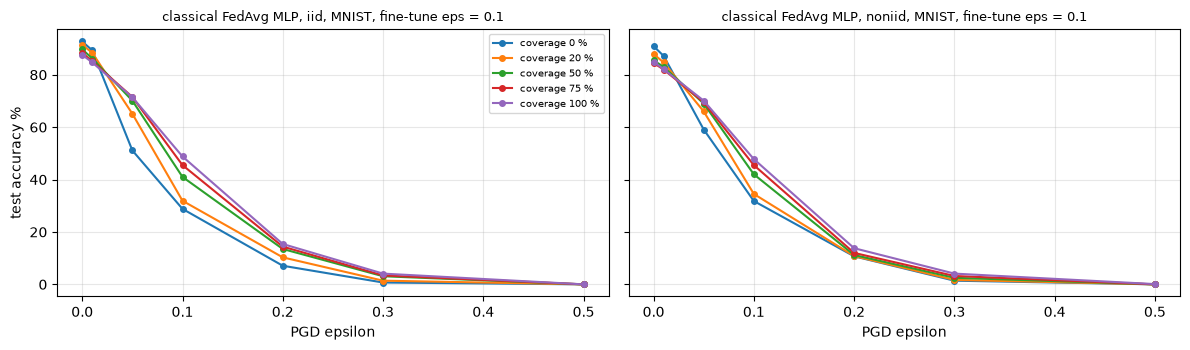

In [16]:
# Classical federated twin: the same FedAvg + partial-coverage PGD adversarial-training protocol, the same 16 inputs, a 163-weight MLP instead of the 24-weight circuit.
# (Not in the paper: it answers "is the behaviour a QUANTUM property or a property of federated adversarial training?")
t0 = time.time(); CL_CASES = [("MNIST", "iid"), ("MNIST", "noniid")]
SURF_MLP = {c: surface(MLP, c[0], c[1], "finetune", "fixed 0.1") for c in CL_CASES}
print(f"classical twin done in {time.time() - t0:.0f} s")
rows = []
for c, S in SURF_MLP.items():
    Sq = SURF4.get(c)
    rows.append(("classical MLP", c[1], round(S[0, 0], 1), round(S[0, 3], 1), round(S[-1, 3], 1), round(robustness_volume(S), 3)))
    if Sq is not None: rows.append(("quantum QNN", c[1], round(Sq[0, 0], 1), round(Sq[0, 3], 1), round(Sq[-1, 3], 1), round(robustness_volume(Sq), 3)))
display(pd.DataFrame(rows, columns=["model", "split", "clean acc % (gamma=0)", "acc % at eps=0.1 (gamma=0)", "acc % at eps=0.1 (gamma=100 %)", "RV"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, c in zip(axes, CL_CASES):
    for gi, g in enumerate(COVERAGES): ax.plot(EPS_GRID, SURF_MLP[c][gi], "o-", ms=4, label=f"coverage {int(g * 100)} %")
    ax.set_xlabel("PGD epsilon"); ax.set_title(f"classical FedAvg MLP, {c[1]}, MNIST, fine-tune eps = 0.1", fontsize=9)
axes[0].set_ylabel("test accuracy %"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 9. Seeds and error bars

The paper reports single runs. With 1000 test images one accuracy value has a binomial standard error of about 1.5 points, so a "gain of 15 points" is well above it but differences of 2-3 points between schedules are not. The headline experiment is repeated for extra seeds
(new clean model, new shards, new random choice of the adversarial clients); `FAST_MODE` runs one seed only.

In [17]:
# Repeat the headline experiment (IID MNIST, fine-tune, fixed eps = 0.1, all coverages) for extra seeds: new clean model, new shards, new random choice of the adversarial clients.
t0 = time.time(); SEEDS = list(range(1 + N_SEEDS_EXTRA))
SEED_SURF = {s: surface(QNN, "MNIST", "iid", "finetune", "fixed 0.1", s) for s in SEEDS}
print(f"{len(SEEDS)} seed(s) done in {time.time() - t0:.0f} s")
A = np.stack([SEED_SURF[s] for s in SEEDS])                      # (seeds, gamma, eps)
def ms(x): return f"{x.mean():.1f} +- {x.std():.1f}" if len(x) > 1 else f"{x.mean():.1f}"
tab = pd.DataFrame({f"eps={e:g}": [ms(A[:, gi, ei]) for gi in range(len(COVERAGES))] for ei, e in enumerate(EPS_GRID)}, index=[f"{int(g * 100)} %" for g in COVERAGES])
def ms3(x): return f"{x.mean():.4f} +- {x.std():.4f}" if len(x) > 1 else f"{x.mean():.4f}"
tab["ARA"] = [ms3(np.array([ara(A[si, gi]) for si in range(len(SEEDS))])) for gi in range(len(COVERAGES))]
print(f"accuracy % (mean +- std over {len(SEEDS)} seed(s), {len(DATA['MNIST']['yte'])} test images each):"); display(tab)
RV_SEEDS = np.array([robustness_volume(A[si]) for si in range(len(SEEDS))])
print("Robustness Volume per seed:", np.round(RV_SEEDS, 4), "| mean", round(RV_SEEDS.mean(), 4), "(paper 0.1513)")
GAIN = {}
for gi in (1, 2):            # 20 % and 50 % coverage
    g_eps = A[:, gi, 1:4].mean(axis=1) - A[:, 0, 1:4].mean(axis=1)        # mean accuracy gain over eps = 0.01, 0.05, 0.1 relative to 0 % coverage
    g_01 = A[:, gi, 3] - A[:, 0, 3]; cost = A[:, 0, 0] - A[:, gi, 0]
    GAIN[COVERAGES[gi]] = dict(mean_gain_eps_le_0p1=g_eps, gain_at_0p1=g_01, clean_cost=cost)
    print(f"coverage {int(COVERAGES[gi] * 100)} %: gain at eps = 0.1: {ms(g_01)} points | mean gain over eps in {{0.01, 0.05, 0.1}}: {ms(g_eps)} points | clean-accuracy cost: {ms(cost)} points")

3 seed(s) done in 381 s
accuracy % (mean +- std over 3 seed(s), 1000 test images each):


,eps=0,eps=0.01,eps=0.05,eps=0.1,eps=0.2,eps=0.3,eps=0.5,ARA
0 %,86.2 +- 1.3,82.0 +- 1.6,54.4 +- 2.4,21.1 +- 1.7,4.2 +- 1.7,0.2 +- 0.0,0.0 +- 0.0,0.1393 +- 0.0081
20 %,85.8 +- 1.3,82.0 +- 1.1,59.2 +- 3.5,25.0 +- 1.6,4.7 +- 1.2,0.3 +- 0.1,0.0 +- 0.0,0.1508 +- 0.0084
50 %,85.0 +- 1.4,81.9 +- 1.6,62.2 +- 3.5,33.0 +- 1.7,5.7 +- 1.4,0.6 +- 0.3,0.0 +- 0.0,0.1680 +- 0.0085
75 %,84.8 +- 1.0,81.5 +- 1.3,63.5 +- 2.9,35.2 +- 1.6,6.1 +- 1.6,0.7 +- 0.4,0.0 +- 0.0,0.1735 +- 0.0067
100 %,85.2 +- 0.3,82.1 +- 0.7,64.0 +- 2.4,37.7 +- 1.6,6.6 +- 1.5,0.8 +- 0.7,0.0 +- 0.0,0.1794 +- 0.0056


Robustness Volume per seed: [0.1558 0.1732 0.1618] | mean 0.1636 (paper 0.1513)
coverage 20 %: gain at eps = 0.1: 3.9 +- 1.5 points | mean gain over eps in {0.01, 0.05, 0.1}: 2.9 +- 0.7 points | clean-accuracy cost: 0.4 +- 0.7 points
coverage 50 %: gain at eps = 0.1: 11.9 +- 1.4 points | mean gain over eps in {0.01, 0.05, 0.1}: 6.5 +- 0.8 points | clean-accuracy cost: 1.2 +- 0.7 points


## 10. How strong is the attack? Calibration of the pixel unit and sensitivity to the PGD steps

The paper does not give the number of PGD iterations, the step size or the pixel scaling of epsilon. The scaling matters a lot: with epsilon measured directly in [0, 1] pixel units the clean federated model is destroyed about twice as early as in the paper's Table I.
We therefore treat one constant, `EPS_UNIT` (the L-infinity radius on pixels in [0, 1] is epsilon x `EPS_UNIT`), as a **calibrated nuisance parameter**: the first table scans it on validation images with the clean federated model and keeps the value whose accuracy-vs-epsilon curve is closest to the paper's Table I QFL row.
This makes the Table I curve in section 4 a calibration target, not an independent confirmation; every other result (Tables II-IV, coverage gains, schedules, non-IID) is a prediction made with that single constant.
The second table shows the effect of the number of PGD iterations (1, 3, 10, 40) on the clean model.

In [18]:
# (1) Calibration of the one unstated constant, EPS_UNIT (pixel unit of epsilon): clean QFL model, IID MNIST, VALIDATION images, 10-step PGD, squared error against the paper's Table I QFL row (eps >= 0.01).
th_s = BASE[("QNN", "MNIST", "iid", 0)][1]; Dm = DATA["MNIST"]; rows = []
unit_saved, steps_saved = EPS_UNIT, PGD_STEPS
paper_q = np.array(PAPER_T1["QFL"])
for unit in [0.3081, 0.35, 0.4, 0.45, 0.5, 0.75, 1.0]:
    EPS_UNIT = unit; c = acc_curve(QNN, th_s, Dm["Xval"], Dm["yval"])
    rows.append((unit, *np.round(c, 1), round(float(((c[1:] - paper_q[1:]) ** 2).sum())), round(ara(c), 3)))
EPS_UNIT = unit_saved
cal = pd.DataFrame(rows, columns=["EPS_UNIT"] + [f"eps={e:g}" for e in EPS_GRID] + ["squared error vs paper", "ARA"]).set_index("EPS_UNIT")
print("paper, Table I (QFL):", PAPER_T1["QFL"], "  ARA", round(ara(paper_q), 3)); display(cal)
print(f"best unit of this grid: {cal['squared error vs paper'].idxmin()}; EPS_UNIT in the configuration: {EPS_UNIT} (calibrated in the full-size run; in FAST_MODE the clean model is smaller and weaker, so the best unit can differ)")

# (2) How much does the number of PGD iterations matter? Clean QFL model, TEST images, EPS_UNIT as configured.
rows = []
for steps in [1, 3, 10, 40]:
    PGD_STEPS = steps
    rows.append((f"{steps} PGD steps" + ("  <- used here" if steps == steps_saved else ""), *np.round(acc_curve(QNN, th_s, Dm["Xte"], Dm["yte"]), 1)))
PGD_STEPS = steps_saved
display(pd.DataFrame(rows, columns=["attack"] + [f"eps={e:g}" for e in EPS_GRID]).set_index("attack"))

paper, Table I (QFL): [79.5, 75.4, 59.6, 24.7, 0.0, 0.0, 0.0]   ARA 0.136


,eps=0,eps=0.01,eps=0.05,eps=0.1,eps=0.2,eps=0.3,eps=0.5,squared error vs paper,ARA
EPS_UNIT,,,,,,,,,
0.3081,84.8,81.7,66.0,40.0,13.4,2.7,0.2,502,0.204
0.3500,84.8,81.0,62.6,35.5,9.1,1.2,0.0,241,0.180
0.4000,84.8,80.7,57.6,30.3,5.2,0.4,0.0,91,0.158
0.4500,84.8,79.8,53.6,25.9,2.9,0.2,0.0,65,0.142
0.5000,84.8,79.6,47.8,21.2,1.8,0.2,0.0,172,0.127
0.7500,84.8,77.7,33.0,6.9,0.2,0.0,0.0,1030,0.088
1.0000,84.8,74.1,21.2,1.8,0.0,0.0,0.0,2001,0.067


best unit of this grid: 0.45; EPS_UNIT in the configuration: 0.45 (calibrated in the full-size run; in FAST_MODE the clean model is smaller and weaker, so the best unit can differ)


,eps=0,eps=0.01,eps=0.05,eps=0.1,eps=0.2,eps=0.3,eps=0.5
attack,,,,,,,
1 PGD steps,84.7,80.4,53.2,23.6,4.2,0.7,0.0
3 PGD steps,84.7,80.4,52.7,22.8,3.5,0.2,0.0
10 PGD steps <- used here,84.7,80.4,52.9,22.7,3.5,0.2,0.0
40 PGD steps,84.7,80.4,52.8,22.7,3.4,0.2,0.0


## 11. Side-by-side comparison with the paper, claim by claim

Every verdict rule is printed next to the claim so that it can be challenged: **reproduced** when the rule is satisfied, **not reached** / **exceeded** when a number falls short of / goes beyond the paper's, **cannot be checked** when an experiment was not run (the `FAST_MODE` subset) or the paper gives no number.

In [19]:
from scipy.stats import spearmanr
V = []          # (claim, paper, this notebook, verdict, rule)
def within(a, b, tol): return "reproduced" if abs(a - b) <= tol else ("exceeded" if a > b else "not reached")
q, c_ = T1["QFL (this notebook)"], T1["Centralized (this notebook)"]
pq, pc = np.array(PAPER_T1["QFL"]), np.array(PAPER_T1["Centralized"])

# ---- Table I ----
V.append(("Table I: clean accuracy, QFL", "79.5 %", f"{q[0]:.1f} %", within(q[0], 79.5, 2.0), "within 2 accuracy points"))
V.append(("Table I: clean accuracy, centralised", "80.6 %", f"{c_[0]:.1f} %", within(c_[0], 80.6, 2.0), "within 2 accuracy points"))
d = float(np.abs(q - pq).mean())
V.append(("Table I: whole QFL curve over the 7 epsilons (CALIBRATED: EPS_UNIT was fitted to this row, so this is not an independent check)", "79.5, 75.4, 59.6, 24.7, 0, 0, 0", ", ".join(f"{x:.1f}" for x in q), "reproduced" if d <= 5 else "not reached", f"mean |difference| over the 7 epsilons <= 5 points (here {d:.1f})"))
dara = ara(q) - ara(c_); pdara = ara(pq) - ara(pc)
V.append(("Federation brings no robustness: QFL as fragile as centralised", f"ARA(QFL) - ARA(centralised) = {pdara:+.3f}", f"{dara:+.3f} (ARA {ara(q):.3f} vs {ara(c_):.3f})", "reproduced" if abs(dara) <= 0.02 else ("exceeded" if dara > 0 else "not reached"), "|ARA difference| <= 0.02 (2 accuracy points on average)"))
V.append(("Both collapse for eps >= 0.3", "<= 0.2 % (Table I)", f"QFL {q[5]:.1f} / {q[6]:.1f} %, centralised {c_[5]:.1f} / {c_[6]:.1f} % at eps 0.3 / 0.5", "reproduced" if max(q[5], c_[5]) <= 10 else "not reached", "accuracy <= 10 % at eps = 0.3 for both"))

# ---- partial coverage and clean cost (IID MNIST, fine-tune, eps = 0.1) ----
gains = np.mean([GAIN[g]["gain_at_0p1"].mean() for g in GAIN]); gains_m = np.mean([GAIN[g]["mean_gain_eps_le_0p1"].mean() for g in GAIN]); cost = np.mean([GAIN[g]["clean_cost"].mean() for g in GAIN])
V.append(("Training only 20-50 % of the clients adversarially lifts accuracy under moderate attack by ~15 points", "~15 pp for eps <= 0.1", f"gain at eps = 0.1: {gains:+.1f} points; mean gain over eps in {{0.01, 0.05, 0.1}}: {gains_m:+.1f} points (mean of 20 % and 50 % coverage, {len(SEEDS)} seed(s))",
          "reproduced" if 10 <= gains <= 20 else ("exceeded" if gains > 20 else "not reached"), "gain at eps = 0.1 within 15 +- 5 points"))
V.append(("... at less than 2 points of clean accuracy", "< 2 pp", f"{cost:+.1f} points (mean of 20 % and 50 % coverage)", "reproduced" if cost < 2 else "not reached", "clean-accuracy loss < 2 points"))

# ---- fine-tune vs scratch ----
rv_ft = robustness_volume(S_ft)
if S_sc is not None:
    rv_sc = robustness_volume(S_sc); rel = 100 * (rv_ft / rv_sc - 1)
    V.append(("Fine-tuning has the higher Robustness Volume than scratch training", "0.1513 vs 0.1443 (+4.8 %, 'about 3-5 %')", f"{rv_ft:.4f} vs {rv_sc:.4f} ({rel:+.1f} %)", "reproduced" if (rv_ft > rv_sc and 1 <= rel <= 10) else ("exceeded" if rel > 10 else "not reached"), "fine-tune > scratch by 1-10 % relative"))
    V.append(("Table II values (RV, fine-tune and scratch)", "0.1513 / 0.1443", f"{rv_ft:.4f} / {rv_sc:.4f}", "reproduced" if max(abs(rv_ft - 0.1513), abs(rv_sc - 0.1443)) <= 0.02 else "not reached", "both within 0.02 (two accuracy points of mean accuracy)"))
    scratch_clean_drop = S_sc[-1, 0] - S_ft[-1, 0]
    V.append(("Scratch training is less stable: clean accuracy at 100 % coverage drops (paper: 69-81 % vs 79-83 % for fine-tuning)", "scratch 69-81 %, fine-tune 79-83 %", f"scratch {S_sc[:, 0].min():.1f}-{S_sc[:, 0].max():.1f} %, fine-tune {S_ft[:, 0].min():.1f}-{S_ft[:, 0].max():.1f} %", "reproduced" if S_sc[:, 0].min() < S_ft[:, 0].min() - 2 else "not reached", "lowest scratch clean accuracy at least 2 points below the lowest fine-tune one"))
else:
    V.append(("Fine-tune vs scratch", "RV 0.1513 vs 0.1443", "scratch not run", "cannot be checked", ""))

# ---- epsilon schedules ----
rvs = {s: robustness_volume(S) for s, S in SURF.items()}; prv = PAPER_T3.loc["RV"]
V.append(("Table III: RV values of the schedules run here", ", ".join(f"{s}: {prv[s]:.3f}" for s in SURF), ", ".join(f"{s}: {v:.3f}" for s, v in rvs.items()),
          "reproduced" if max(abs(rvs[s] - prv[s]) for s in SURF) <= 0.02 else "not reached", "all within 0.02"))
if len(SURF) >= 4:
    rho = spearmanr([rvs[s] for s in SURF], [prv[s] for s in SURF])[0]
    V.append(("Table III: moderate mix has the best RV, low mix the worst", "best 0.153 (moderate), worst 0.142 (low mix)", f"best: {max(rvs, key=rvs.get)}, worst: {min(rvs, key=rvs.get)}; Spearman with the paper's order {rho:+.2f}", "reproduced" if (max(rvs, key=rvs.get) == "mix [0.1,0.15,0.2]" and min(rvs, key=rvs.get) == "mix [0.01,0.02,0.05]") else "not reached", "both extremes identical to the paper"))
else:
    V.append(("Table III: moderate mix best, low mix worst", "0.153 / 0.142", "only two schedules run in FAST_MODE", "cannot be checked", ""))
mm, sm, f1 = "mix [0.1,0.15,0.2]", "mix [0.3,0.4,0.5]", "fixed 0.1"
if sm in SURF:
    a75 = (SURF[mm][3, 3], SURF[sm][3, 3]); a100 = (SURF[sm][4, 3], SURF[mm][4, 3], SURF[f1][4, 3])
    V.append(("75 % coverage: the strong mix collapses at eps = 0.1 relative to the moderate mix", "moderate ~35 %, strong 21 %", f"moderate {a75[0]:.1f} %, strong {a75[1]:.1f} %", "reproduced" if a75[0] - a75[1] >= 5 else "not reached", "moderate mix at least 5 points above the strong mix"))
    V.append(("100 % coverage: the strong mix has the highest accuracy at eps = 0.1", "strong 43.0 > moderate 37.7 > fixed 36.0", f"strong {a100[0]:.1f}, moderate {a100[1]:.1f}, fixed 0.1 {a100[2]:.1f}", "reproduced" if a100[0] >= max(a100[1:]) else "not reached", "strong mix at least as high as both others"))
else:
    V.append(("Strong mix at 75 % / 100 % coverage", "see paper", "strong mix not run in FAST_MODE", "cannot be checked", ""))

# ---- non-IID ----
for ds, claim in (("MNIST", -49), ("FMNIST", -60)):
    if (ds, "noniid") in SURF4:
        a, b = robustness_volume(SURF4[(ds, "iid")]), robustness_volume(SURF4[(ds, "noniid")]); red = 100 * (b / a - 1)
        V.append((f"Sorted non-IID roughly halves the Robustness Volume ({FULL_NAME[ds]})", f"{claim} % ({PAPER_T4[(ds, 'iid')][0]} -> {PAPER_T4[(ds, 'noniid')][0]})", f"{red:+.0f} % ({a:.3f} -> {b:.3f})", "reproduced" if abs(red - claim) <= 15 else ("exceeded" if red < claim else "not reached"), "reduction within 15 percentage points of the paper's"))
        An = SURF4[(ds, "noniid")]; ar_ = [ara(r) for r in An]
        V.append((f"Non-IID: adversarial-training coverage does not help ({FULL_NAME[ds]})", "0 % coverage curve is the best", f"ARA by coverage: " + ", ".join(f"{int(g * 100)}%: {x:.3f}" for g, x in zip(COVERAGES, ar_)), "reproduced" if ar_[0] >= max(ar_[1:]) - 0.005 else "not reached", "ARA(0 %) within 0.005 of the best coverage"))
    else:
        V.append((f"Sorted non-IID halves RV ({FULL_NAME[ds]})", f"{claim} %", "not run", "cannot be checked", ""))
vals = [(k, SURF4[k]) for k in PAPER_T4 if k in SURF4]
V.append(("Table IV: RV values of the four dataset / split cases", "0.151, 0.077, 0.154, 0.062", ", ".join(f"{robustness_volume(S):.3f}" for _, S in vals), "reproduced" if all(abs(robustness_volume(S) - PAPER_T4[k][0]) <= 0.02 for k, S in vals) else "not reached", "all within 0.02"))
V.append(("Hardware / shot-noise behaviour", "simulation only, parameter-shift", "exact simulator (no shot noise); not tested", "cannot be checked", "no hardware or shot-noise experiment in the paper"))
VER = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict", "rule"])
pd.set_option("display.max_colwidth", 140, "display.width", 250); display(VER)
print(VER["verdict"].value_counts().to_string())

,claim,paper,this notebook,verdict,rule
0,"Table I: clean accuracy, QFL",79.5 %,84.7 %,exceeded,within 2 accuracy points
1,"Table I: clean accuracy, centralised",80.6 %,87.2 %,exceeded,within 2 accuracy points
2,"Table I: whole QFL curve over the 7 epsilons (CALIBRATED: EPS_UNIT was fitted to this row, so this is not an independent check)","79.5, 75.4, 59.6, 24.7, 0, 0, 0","84.7, 80.4, 52.9, 22.7, 3.5, 0.2, 0.0",reproduced,mean |difference| over the 7 epsilons <= 5 points (here 3.2)
3,Federation brings no robustness: QFL as fragile as centralised,ARA(QFL) - ARA(centralised) = -0.012,-0.006 (ARA 0.138 vs 0.143),reproduced,|ARA difference| <= 0.02 (2 accuracy points on average)
4,Both collapse for eps >= 0.3,<= 0.2 % (Table I),"QFL 0.2 / 0.0 %, centralised 0.1 / 0.0 % at eps 0.3 / 0.5",reproduced,accuracy <= 10 % at eps = 0.3 for both
5,Training only 20-50 % of the clients adversarially lifts accuracy under moderate attack by ~15 points,~15 pp for eps <= 0.1,"gain at eps = 0.1: +7.9 points; mean gain over eps in {0.01, 0.05, 0.1}: +4.7 points (mean of 20 % and 50 % coverage, 3 seed(s))",not reached,gain at eps = 0.1 within 15 +- 5 points
6,... at less than 2 points of clean accuracy,< 2 pp,+0.8 points (mean of 20 % and 50 % coverage),reproduced,clean-accuracy loss < 2 points
7,Fine-tuning has the higher Robustness Volume than scratch training,"0.1513 vs 0.1443 (+4.8 %, 'about 3-5 %')",0.1558 vs 0.1467 (+6.2 %),reproduced,fine-tune > scratch by 1-10 % relative
8,"Table II values (RV, fine-tune and scratch)",0.1513 / 0.1443,0.1558 / 0.1467,reproduced,both within 0.02 (two accuracy points of mean accuracy)
9,Scratch training is less stable: clean accuracy at 100 % coverage drops (paper: 69-81 % vs 79-83 % for fine-tuning),"scratch 69-81 %, fine-tune 79-83 %","scratch 78.6-86.9 %, fine-tune 83.1-85.0 %",reproduced,lowest scratch clean accuracy at least 2 points below the lowest fine-tune one


verdict
reproduced           11
not reached           6
exceeded              2
cannot be checked     1


## 11b. Reading the paper critically

*The numbers quoted here come from the stored full run (`FAST_MODE = False`: 18000 training / 1000 test images, 50 + 30 federated rounds, 20 scratch rounds, five schedules, three seeds of the headline sweep). A `FAST_MODE` re-run uses 3000 / 400 images, 15 + 8 rounds and two schedules, and is much noisier.*

**What the re-run supports.**
* **Federation alone brings no robustness.** Centralised and federated models have practically the same accuracy-vs-epsilon curve (ARA 0.143 vs 0.138; paper 0.148 vs 0.136) and both are at about 0 % from epsilon 0.3 on. A classical federated MLP is also attacked easily (ARA 0.167).
* **Fine-tuning beats scratch training.** Robustness Volume 0.156 vs 0.147 (+6 %, paper +5 %); both Table II values land within 0.005 of the paper's. The scratch coverage curve is non-monotone (ARA 0.139, 0.136, 0.150, 0.169, 0.124 for 0-100 % coverage) while fine-tuning rises monotonically (0.137, 0.144, 0.158, 0.165, 0.172), as the paper describes for its Fig. 2.
* **Partial coverage helps, at almost no clean-accuracy cost.** With three seeds, training half of the clients adversarially lifts the accuracy at epsilon = 0.1 by 11.9 +- 1.4 points for 1.2 +- 0.7 points of clean accuracy; 75 % coverage gives +14 and 100 % coverage +17 points. The seed-mean ARA rises with coverage (0.139, 0.151, 0.168, 0.174, 0.179 for 0-100 %).
* **A strong epsilon mix hurts at 75 % coverage** (accuracy at epsilon = 0.1: 21.5 % against 36.2 % for the moderate mix), as in the paper (21 % vs about 35 %).
* **Label-sorted MNIST halves the robustness of the quantum model** (RV 0.156 -> 0.098, -37 %; paper -49 %) and adversarial-training coverage does not help there (ARA 0.124 with no adversarial client, at most 0.102 with any).

**What it does not support, and why each number needs care.**
* **The "about 15 points" headline is only reached at higher coverage.** At 20 % coverage the gain at epsilon = 0.1 is 3.9 +- 1.5 points, at 50 % it is 11.9 +- 1.4 points. The statement "20-50 %" in the abstract is therefore optimistic for this implementation; the 20 % case is within a few seed standard deviations of no gain.
* **The strong epsilon mix does not win at 100 % coverage.** The paper reports 43 % at epsilon = 0.1; here it is 5 % and the mix has the *lowest* RV of all schedules (0.126; ARA at full coverage 0.059). With epsilon up to 0.5 x 0.45 = 0.225 on pixels of mean value 0.13, adversarial training on half of every mini-batch pushes the 24-parameter circuit towards a constant predictor. Whether the paper's pixel scale makes that regime benign cannot be told from the text.
* **The best schedule is not distinguishable from the runner-up.** The moderate mix has the best RV (0.159) but the fixed 0.1 schedule is at 0.156; the seed-to-seed standard deviation of RV is about 0.007 (three seeds: 0.156, 0.173, 0.162). The paper's own spread between its three best schedules (0.151-0.153) is smaller still, and it reports a single run per cell. The ordering of Table III is not statistically supported, in the paper or here (Spearman correlation with the paper's order +0.70).
* **Fashion-MNIST and its sorted split do not reproduce.** RV 0.233 (IID) and 0.165 (sorted) against 0.154 and 0.062, and on sorted Fashion-MNIST adversarial training *helps* (ARA 0.102 without, 0.189 with half of the clients), the opposite of the paper's "gains reverse". Two reasons: the pixel unit `EPS_UNIT` was calibrated on MNIST and transfers poorly (Fashion-MNIST pixels are about 2.4 times larger on average, so the same epsilon is a smaller relative perturbation), and the sorted runs are noisy (clean accuracy of the final model ranges from 64 % to 87 % across coverages for one seed, because FedAvg of single-class clients oscillates).
* **Clean accuracy is higher than the paper's** (84.7 % federated and 87.2 % centralised against 79.5 % and 80.6 %). The paper's unstated optimiser settings, read-out and image reduction decide this; the centralised model is not 'better than federated' by a meaningful margin in either study.
* **Table I's attack curve is calibrated, not confirmed.** The paper does not give the pixel scale of epsilon. With raw [0, 1] pixels our clean model collapses about twice as early; one constant (`EPS_UNIT = 0.45`, section 10) was fitted to the paper's QFL row, after which the curve agrees within about 3 points on average. Everything else is a prediction with that constant. The attack is also cheap: one PGD step is nearly as strong as forty (accuracy at epsilon = 0.1: 23.6 % vs 22.7 %).

**What the paper does not test, and what the extras here show.**
* **The non-IID damage is specific to this small circuit, not to federation.** The classical MLP (163 weights) trained with the identical protocol keeps its robustness on sorted data (RV 0.205 IID, 0.203 sorted; accuracy at epsilon = 0.1 with full coverage 49 % IID, 48 % sorted), while the 24-weight circuit drops from RV 0.156 to 0.098 and, with full coverage on sorted data, to 6.8 % at epsilon = 0.1. The paper's conclusion that heterogeneity is "the dominant risk" holds for a capacity-starved model that has to average label-specialised weights; it is not shown to be a property of quantum federated learning in general.
* **Quantum vs classical.** On IID MNIST the classical twin is more accurate (92.7 % vs 84.5 %) and has the larger RV (0.205 vs 0.156). No claim in the paper compares against a classical federated model, so the quantum model's robustness is not put in context there.
* **Transfer to classical models.** PGD examples crafted against the quantum model transfer only partly: at epsilon = 0.05 an RBF-SVC keeps 72 % accuracy and a RandomForest 52 %, against 53 % for the quantum model itself, and at epsilon = 0.1 both keep 37 %. Part of the perturbation is specific to the amplitude-encoding geometry of the circuit.
* **What is not tested anywhere.** Shot noise (the paper simulates with parameter-shift but gives no shot count; here the simulator is exact), hardware noise, adaptive attacks (random restarts, gradient-free attacks), and a stronger threat model in which the adversary also poisons the clients. Even the best defence leaves only about 37 % accuracy at epsilon = 0.1 against 85 % clean: "robust" here means *less fragile*, not safe.
* **Unspecified details that move the numbers:** the ansatz and read-out, the logit scale and loss, how 8 x 8 images enter a 4-qubit register, the pixel scale of epsilon, PGD steps and step size, local steps and learning rate, which clients are adversarial, the epsilon grid, and the number of seeds (one in the paper).

## 12. Exercises

1. **Which clients are adversarial?** The notebook takes the first `round(gamma x 15)` clients of one random permutation. In the sorted non-IID split this decides *which classes* are defended. Repeat the non-IID sweep for 5 different permutations (change `get_setup`) and report the spread of the Robustness Volume. How much of the paper's "coverage does not help" is a property of which clients are covered?
2. **Weaker or stronger attack.** Section 10 shows that the paper's Table I curve fixes only one constant, `EPS_UNIT`. Re-run the fine-tune sweep with `EPS_UNIT = 0.3081` and with `EPS_UNIT = 1.0`. Do the ranking of the five schedules (Table III) and the fine-tune vs scratch ordering survive?
3. **Random start and restarts.** Add a uniform random start inside the epsilon ball to `pgd` and take the worst of 5 restarts at evaluation time. Does the accuracy at epsilon = 0.1 of the adversarially trained models drop (gradient masking), or does it stay put?
4. **Shot noise.** The notebook simulates exactly. Replace `QNN.expvals` by an estimate from `SHOTS = 1000` samples (sample the outcome of every `Z` measurement) and re-evaluate the clean federated model under PGD computed on the exact model. How much of the robustness is destroyed by shot noise alone, and does adversarial training change that?
5. **Server-side defences for non-IID data.** The paper proposes a small IID reference set shared by all clients as future work. Give every client 5 % of its data from a pooled IID set (keep the rest sorted) and repeat the non-IID experiment. How much of the lost Robustness Volume comes back, for the quantum model and for the classical MLP?